# Course Topic 2: High-Dimensional Visual Style Clustering (MMDS Week 6)
## Unsupervised Discovery of Photographic Genres & Hero Curation

### 1. Conceptual Framing
While Course Topic 1 (PCY) decomposed photographic attributes into discrete market basket rules, unsupervised clustering treats visual style as a continuous geometry. We aim to:
1. **Partition the 512-Dimensional CLIP Feature Space:** Group photos into organic stylistic and thematic clusters (e.g., moody portraits, alpine vistas, architectural minimalism) without human labeling.
2. **Evaluate Clustering Quality:** Standardize cluster evaluation using syllabus-specified metrics:
   * **Davies-Bouldin Index ($DB$):** Evaluates cluster separation and compactness. Lower values indicate tighter, better-separated clusters:
     $$R_{ij} = \frac{s_i + s_j}{d(c_i, c_j)}, \quad DB = \frac{1}{k} \sum_{i=1}^k \max_{j \neq i} R_{ij}$$
   * **Silhouette Coefficient:** Measures how well-assigned each sample is to its cluster relative to its nearest neighboring cluster.
3. **Aesthetic-Driven "Hero Selection":** For each discovered visual cluster, identify the **Hero Thumbnail** — the photograph maximizing predicted aesthetic score $\hat{y}$ within that stylistic cluster.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import davies_bouldin_score, silhouette_score
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# 1. Prepare Feature Vectors from Scored Unsplash Table
# -----------------------------------------------------------------------------
data_path = Path("data") / "unsplash_scored_predictions.parquet"
df_photos = pd.read_parquet(data_path)

# Extract 512-dim normalized CLIP vectors
X_clip = np.vstack(df_photos["clip_embedding"].values).astype(np.float32)
y_scores = df_photos["predicted_aesthetic_score"].to_numpy()

print(f"Loaded {X_clip.shape[0]:,} photos with {X_clip.shape[1]}-dimensional embeddings.")

# -----------------------------------------------------------------------------
# 2. PCA Projection for Density Regularization & 2D Visualization
# -----------------------------------------------------------------------------
# Reduce to 50 principal components to mitigate curse of dimensionality while retaining ~80% variance
pca_50 = PCA(n_components=50, random_state=42)
X_pca50 = pca_50.fit_transform(X_clip)
var_retained = np.sum(pca_50.explained_variance_ratio_) * 100
print(f"50-Component PCA preserves {var_retained:.2f}% of total visual variance.")

# 2D projection strictly for scatter plotting
pca_2d = PCA(n_components=2, random_state=42)
X_2d = pca_2d.fit_transform(X_clip)

# -----------------------------------------------------------------------------
# 3. K-Means Parameter Sweep & Davies-Bouldin Optimization
# -----------------------------------------------------------------------------
k_candidates = [4, 6, 8, 10, 12, 16]
db_scores = []
inertias = []

# Subsample 5k points for fast silhouette calculation
sample_idx = np.random.RandomState(42).choice(len(X_pca50), size=5000, replace=False)

for k in k_candidates:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_pca50)
    
    db = davies_bouldin_score(X_pca50, labels)
    db_scores.append(db)
    inertias.append(km.inertia_)
    print(f"k = {k:2d} | Davies-Bouldin: {db:.4f} | Inertia: {km.inertia_:,.1f}")

optimal_k = k_candidates[np.argmin(db_scores)]
print(f"\nOptimal K-Means clusters (minimizing DB Index): k = {optimal_k}")

# Fit final optimal model
final_kmeans = KMeans(n_clusters=optimal_k, n_init=10, random_state=42)
df_photos["cluster_id"] = final_kmeans.fit_predict(X_pca50)

Loaded 24,993 photos with 512-dimensional embeddings.
50-Component PCA preserves 67.92% of total visual variance.
k =  4 | Davies-Bouldin: 2.9337 | Inertia: 4,987.9
k =  6 | Davies-Bouldin: 2.6577 | Inertia: 4,664.7
k =  8 | Davies-Bouldin: 2.6306 | Inertia: 4,416.3
k = 10 | Davies-Bouldin: 2.4908 | Inertia: 4,239.7
k = 12 | Davies-Bouldin: 2.5743 | Inertia: 4,100.1
k = 16 | Davies-Bouldin: 2.4712 | Inertia: 3,894.8

Optimal K-Means clusters (minimizing DB Index): k = 16


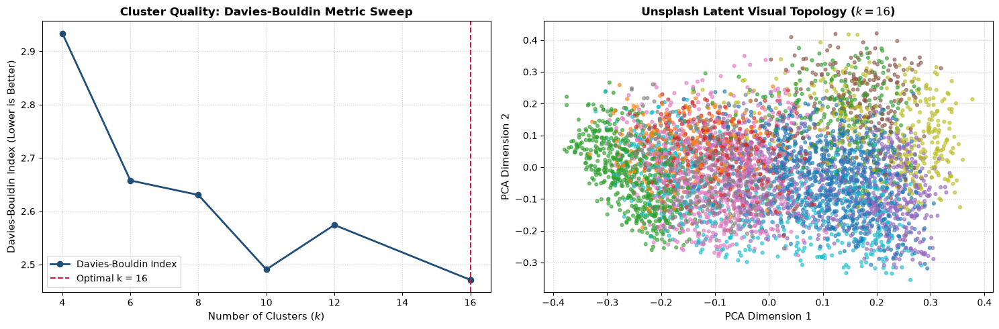

In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Davies-Bouldin Index vs k
ax1.plot(k_candidates, db_scores, marker="o", color="#1f4e79", linewidth=2, label="Davies-Bouldin Index")
ax1.axvline(optimal_k, color="crimson", linestyle="--", label=f"Optimal k = {optimal_k}")
ax1.set_xlabel("Number of Clusters ($k$)", fontsize=11)
ax1.set_ylabel("Davies-Bouldin Index (Lower is Better)", fontsize=11)
ax1.set_title("Cluster Quality: Davies-Bouldin Metric Sweep", fontsize=12, fontweight="bold")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend()

# Plot 2: 2D Visual Landscape Colored by Discovered Style Clusters
scatter = ax2.scatter(
    X_2d[sample_idx, 0], X_2d[sample_idx, 1],
    c=df_photos.iloc[sample_idx]["cluster_id"],
    cmap="tab10",
    s=12,
    alpha=0.6
)
ax2.set_xlabel("PCA Dimension 1", fontsize=11)
ax2.set_ylabel("PCA Dimension 2", fontsize=11)
ax2.set_title(f"Unsplash Latent Visual Topology ($k={optimal_k}$)", fontsize=12, fontweight="bold")
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

CLUSTER PROFILES & AESTHETIC HERO SELECTION (k = 16)

[CLUSTER 0] Photos: 2,069 (8.3%) | Mean Score: 5.068 | High Aesthetic %: 7.3%
  Hero Photo ID : aj_0AGzw6Qo
  Hero Score    : 6.326 (Max in cluster)
  Camera Setup  : SONY ILCE-6500 | f/1.7 | ISO 800.0


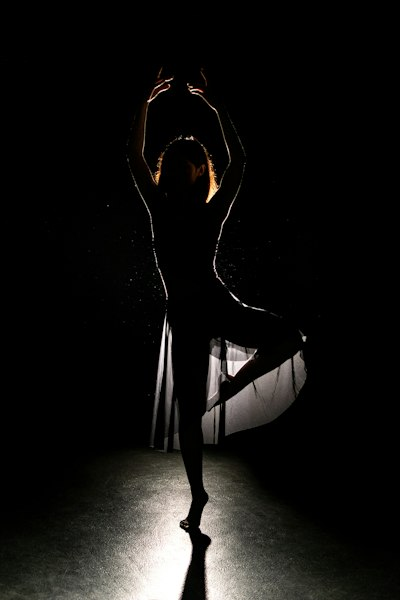

------------------------------------------------------------------------------------------

[CLUSTER 1] Photos: 2,139 (8.6%) | Mean Score: 5.053 | High Aesthetic %: 3.4%
  Hero Photo ID : KCnX0ux2jFo
  Hero Score    : 6.339 (Max in cluster)
  Camera Setup  : NIKON CORPORATION NIKON D850 | f/6.3 | ISO 125.0


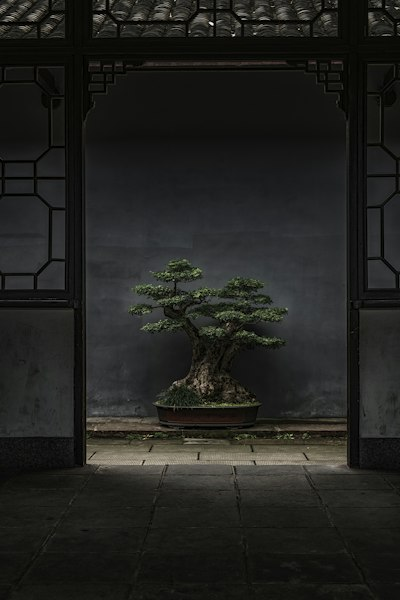

------------------------------------------------------------------------------------------

[CLUSTER 2] Photos: 1,122 (4.5%) | Mean Score: 5.564 | High Aesthetic %: 47.4%
  Hero Photo ID : SD0OiLT-Nkg
  Hero Score    : 6.612 (Max in cluster)
  Camera Setup  : nan nan | f/nan | ISO nan


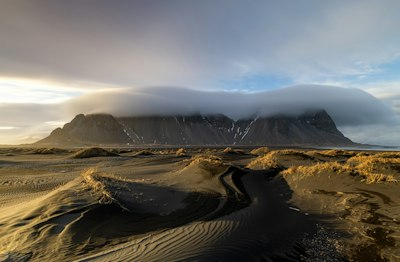

------------------------------------------------------------------------------------------

[CLUSTER 3] Photos: 2,733 (10.9%) | Mean Score: 5.600 | High Aesthetic %: 50.4%
  Hero Photo ID : NY5uagc167k
  Hero Score    : 6.700 (Max in cluster)
  Camera Setup  : SONY ILCE-7RM4 | f/9 | ISO 200.0


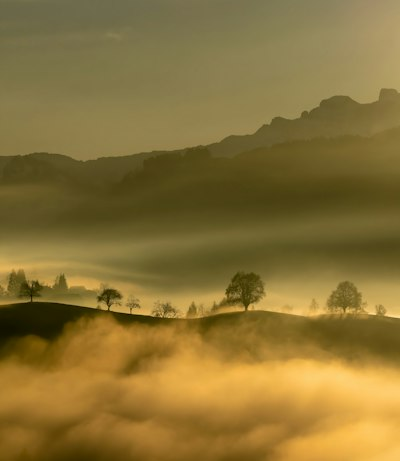

------------------------------------------------------------------------------------------

[CLUSTER 4] Photos: 1,036 (4.1%) | Mean Score: 5.387 | High Aesthetic %: 24.8%
  Hero Photo ID : Cbw4eG-bS8M
  Hero Score    : 6.336 (Max in cluster)
  Camera Setup  : SONY ILCE-7RM3 | f/1.4 | ISO 100.0


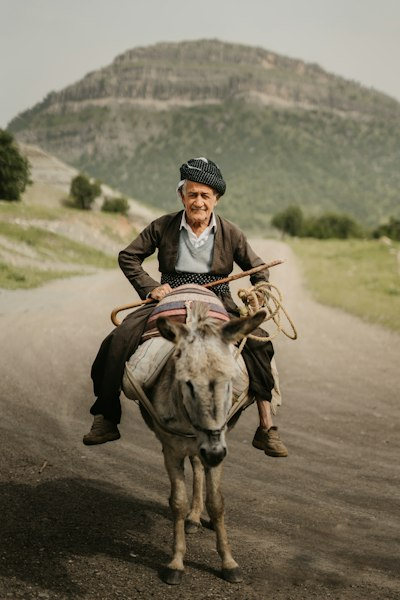

------------------------------------------------------------------------------------------

[CLUSTER 5] Photos: 1,495 (6.0%) | Mean Score: 5.328 | High Aesthetic %: 22.7%
  Hero Photo ID : nlF8qaFWI0w
  Hero Score    : 6.570 (Max in cluster)
  Camera Setup  : FUJIFILM GFX 50S | f/16 | ISO 400.0


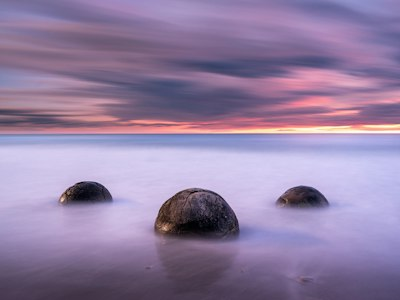

------------------------------------------------------------------------------------------

[CLUSTER 6] Photos: 2,078 (8.3%) | Mean Score: 5.096 | High Aesthetic %: 4.8%
  Hero Photo ID : 52g-HBU9klU
  Hero Score    : 6.196 (Max in cluster)
  Camera Setup  : SONY ILCE-7 | f/2.8 | ISO 50.0


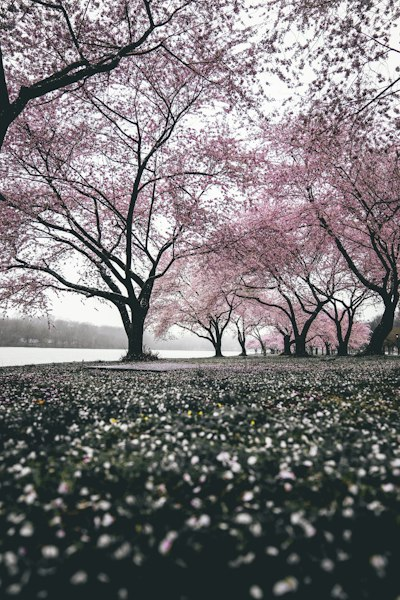

------------------------------------------------------------------------------------------

[CLUSTER 7] Photos: 1,292 (5.2%) | Mean Score: 5.387 | High Aesthetic %: 29.4%
  Hero Photo ID : UMftJn4b9yM
  Hero Score    : 6.507 (Max in cluster)
  Camera Setup  : Canon Canon EOS 500D | f/11.0 | ISO 200.0


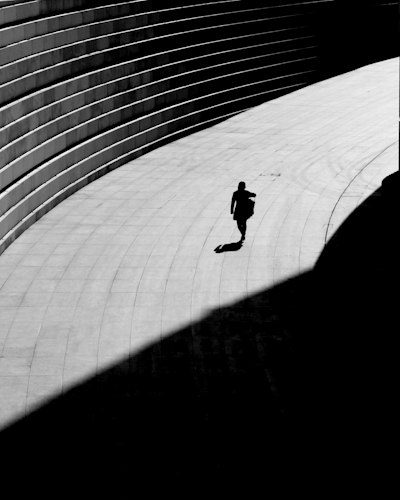

------------------------------------------------------------------------------------------

[CLUSTER 8] Photos: 1,032 (4.1%) | Mean Score: 5.313 | High Aesthetic %: 19.4%
  Hero Photo ID : PZWvAnFqO_M
  Hero Score    : 6.251 (Max in cluster)
  Camera Setup  : Canon Canon EOS 5D Mark IV | f/4.0 | ISO 500.0


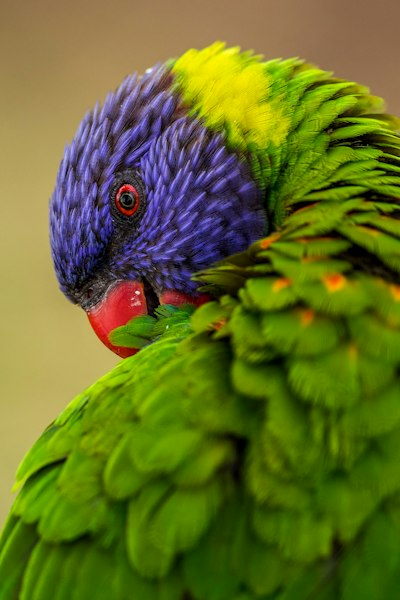

------------------------------------------------------------------------------------------

[CLUSTER 9] Photos: 2,012 (8.1%) | Mean Score: 5.373 | High Aesthetic %: 22.1%
  Hero Photo ID : Hm0C-IRz8I0
  Hero Score    : 6.608 (Max in cluster)
  Camera Setup  : NIKON CORPORATION NIKON D800E | f/16.0 | ISO 220.0


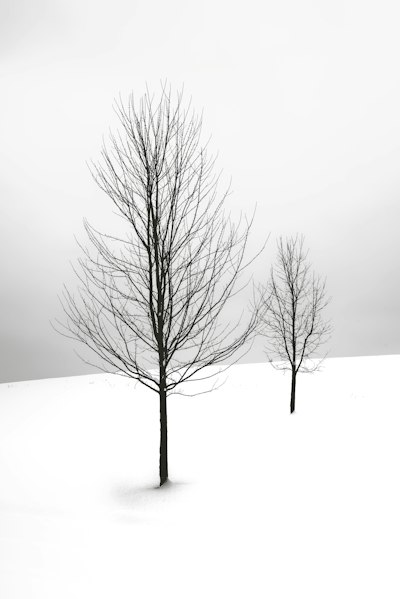

------------------------------------------------------------------------------------------

[CLUSTER 10] Photos: 1,273 (5.1%) | Mean Score: 5.557 | High Aesthetic %: 49.8%
  Hero Photo ID : v41Z5HCahzo
  Hero Score    : 6.658 (Max in cluster)
  Camera Setup  : NIKON CORPORATION NIKON D750 | f/1.8 | ISO 6400.0


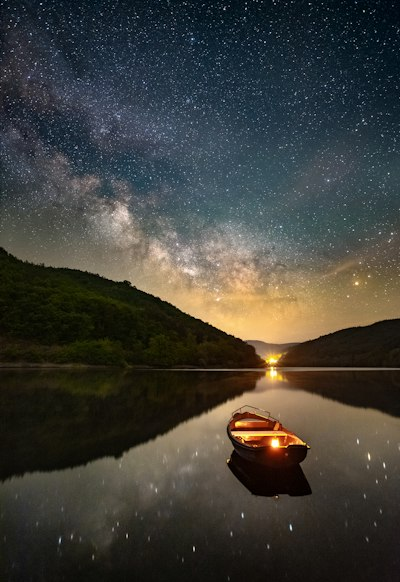

------------------------------------------------------------------------------------------

[CLUSTER 11] Photos: 2,399 (9.6%) | Mean Score: 5.435 | High Aesthetic %: 29.2%
  Hero Photo ID : KVLzhuroc4A
  Hero Score    : 6.444 (Max in cluster)
  Camera Setup  : Nikon D750 | f/8 | ISO 50.0


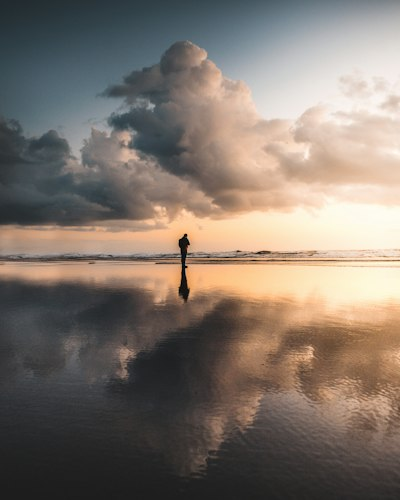

------------------------------------------------------------------------------------------

[CLUSTER 12] Photos: 1,261 (5.0%) | Mean Score: 5.260 | High Aesthetic %: 12.1%
  Hero Photo ID : CM1oVEUzsNM
  Hero Score    : 6.192 (Max in cluster)
  Camera Setup  : FUJIFILM X-T2 | f/5.0 | ISO 400.0


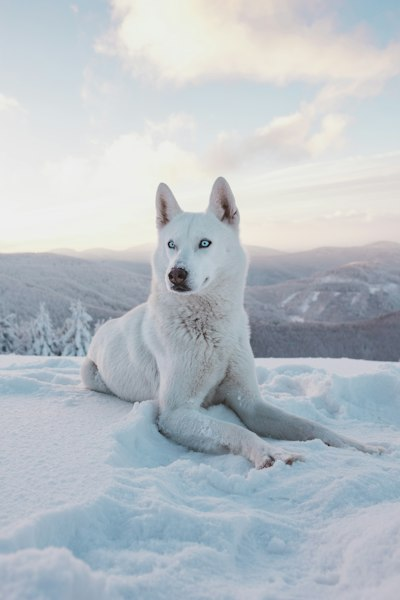

------------------------------------------------------------------------------------------

[CLUSTER 13] Photos: 614 (2.5%) | Mean Score: 5.225 | High Aesthetic %: 15.5%
  Hero Photo ID : jwraMZtxBHs
  Hero Score    : 6.266 (Max in cluster)
  Camera Setup  : nan nan | f/nan | ISO nan


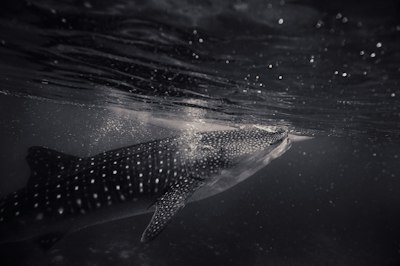

------------------------------------------------------------------------------------------

[CLUSTER 14] Photos: 1,550 (6.2%) | Mean Score: 5.364 | High Aesthetic %: 23.5%
  Hero Photo ID : SM3EsVq4Kyk
  Hero Score    : 6.629 (Max in cluster)
  Camera Setup  : NIKON CORPORATION NIKON D5300 | f/9.5 | ISO 125.0


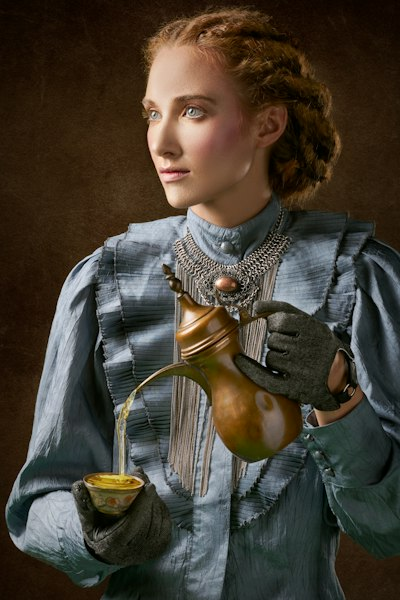

------------------------------------------------------------------------------------------

[CLUSTER 15] Photos: 888 (3.6%) | Mean Score: 5.598 | High Aesthetic %: 50.6%
  Hero Photo ID : -YiYSrdKXUc
  Hero Score    : 6.628 (Max in cluster)
  Camera Setup  : Canon Canon EOS 5DS R | f/2.8 | ISO 640.0


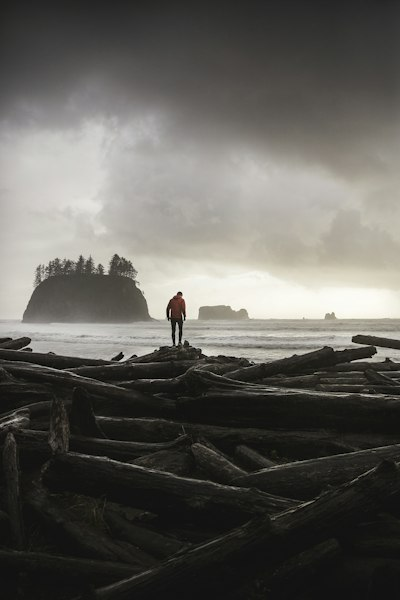

------------------------------------------------------------------------------------------


In [3]:
import io
import requests
from PIL import Image
from IPython.display import display

session = requests.Session()

print("=" * 90)
print(f"CLUSTER PROFILES & AESTHETIC HERO SELECTION (k = {optimal_k})")
print("=" * 90)

for cid in sorted(df_photos["cluster_id"].unique()):
    cluster_df = df_photos[df_photos["cluster_id"] == cid]
    cluster_size = len(cluster_df)
    pct = (cluster_size / len(df_photos)) * 100
    mean_score = cluster_df["predicted_aesthetic_score"].mean()
    high_pct = (cluster_df["aesthetic_bin"] == "High_Aesthetic").mean() * 100
    
    # Identify the "Hero Photo" maximizing aesthetic score
    hero_row = cluster_df.loc[cluster_df["predicted_aesthetic_score"].idxmax()]
    
    print(f"\n[CLUSTER {cid}] Photos: {cluster_size:,} ({pct:.1f}%) | Mean Score: {mean_score:.3f} | High Aesthetic %: {high_pct:.1f}%")
    print(f"  Hero Photo ID : {hero_row['photo_id']}")
    print(f"  Hero Score    : {hero_row['predicted_aesthetic_score']:.3f} (Max in cluster)")
    print(f"  Camera Setup  : {hero_row.get('exif_camera_make', 'N/A')} {hero_row.get('exif_camera_model', '')} | f/{hero_row.get('exif_aperture_value', 'N/A')} | ISO {hero_row.get('exif_iso', 'N/A')}")
    
    # Render Hero Thumbnail
    url = str(hero_row["photo_image_url"])
    fetch_url = f"{url}?w=400&q=80" if "?" not in url else f"{url}&w=400&q=80"
    try:
        res = session.get(fetch_url, timeout=10)
        if res.status_code == 200:
            display(Image.open(io.BytesIO(res.content)))
    except Exception as e:
        print(f"  Preview load error: {e}")
        
    print("-" * 90)

In [5]:
import glob
from pathlib import Path
import pandas as pd

# Build photo_to_tags mapping if not already in memory
if "photo_to_tags" not in globals():
  raw_dir = Path("data/unsplash-research-dataset-lite-latest")
  # Fallback to Path("data") if the nested folder doesn't exist
  kw_files = sorted(glob.glob(str(raw_dir / "keywords.*sv*"))) or sorted(
      glob.glob("data/keywords.*sv*")
  )

  if kw_files:
    print(f"Loading keywords from {kw_files[0]}...")
    df_kw = pd.concat(
        [
            pd.read_csv(f, sep="\t", header=0, low_memory=False)
            for f in kw_files
        ],
        ignore_index=True,
    )
    if "confidence" in df_kw.columns:
      df_kw = df_kw[df_kw["confidence"] >= 0.5]

    photo_to_tags = (
        df_kw.groupby("photo_id")["keyword"]
        .apply(lambda tags: [
            f"Tag_{str(t).lower().strip().replace(' ', '_')}" for t in tags[:6]
        ])
        .to_dict()
    )
    print(f"Loaded tags for {len(photo_to_tags):,} photos.")
  else:
    photo_to_tags = {}
    print(
        "Warning: keywords file not found; proceeding without keyword tags."
    )

Loading keywords from data\unsplash-research-dataset-lite-latest\keywords.tsv000...
Loaded tags for 25,000 photos.


3x3 VISUAL GALLERIES (9 PHOTOS PER CLUSTER) | k = 16

[CLUSTER  0] Size: 2,069 ( 8.3%) | Mean Score: 5.068 | High Aesthetic:  7.3% | Frequent Aperture: f/2.8
  Dominant Semantic Tags: outdoors, nature, grey, water, animal, texture, pattern, plant


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


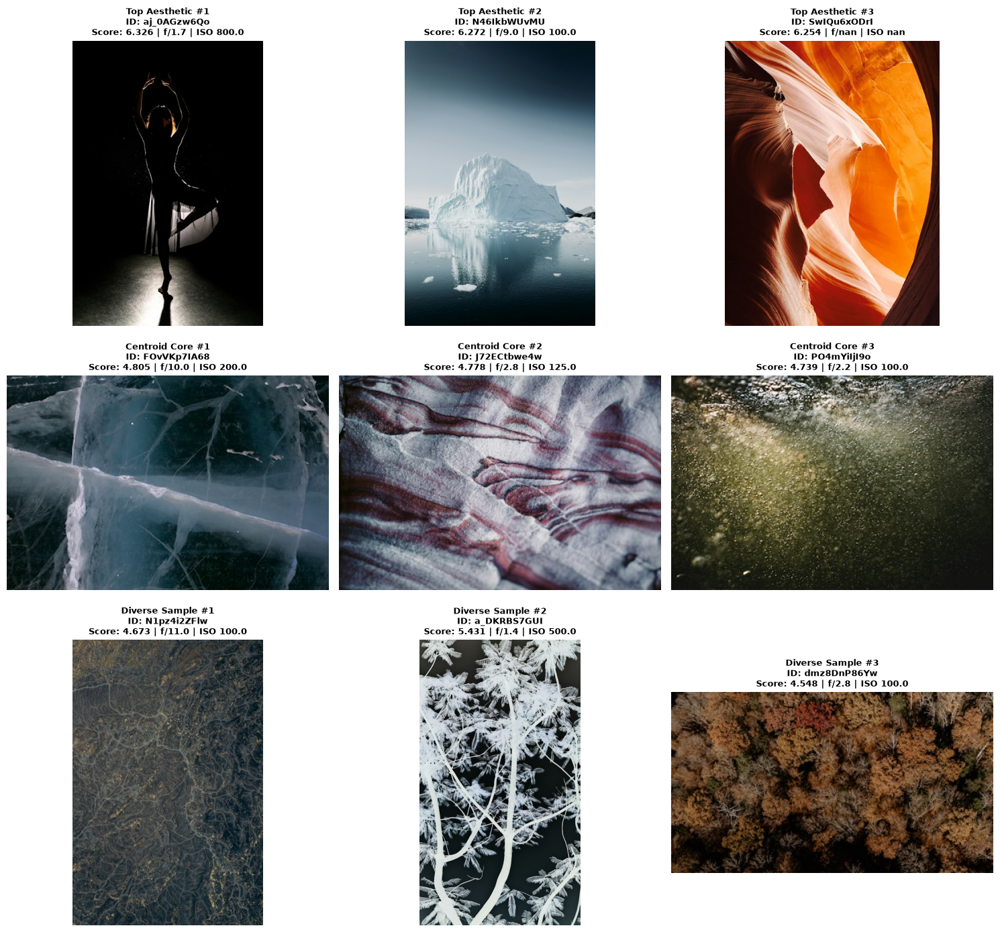

----------------------------------------------------------------------------------------------------

[CLUSTER  1] Size: 2,139 ( 8.6%) | Mean Score: 5.053 | High Aesthetic:  3.4% | Frequent Aperture: f/2.8
  Dominant Semantic Tags: plant, grey, leaf, tree, nature, green, flower, blossom


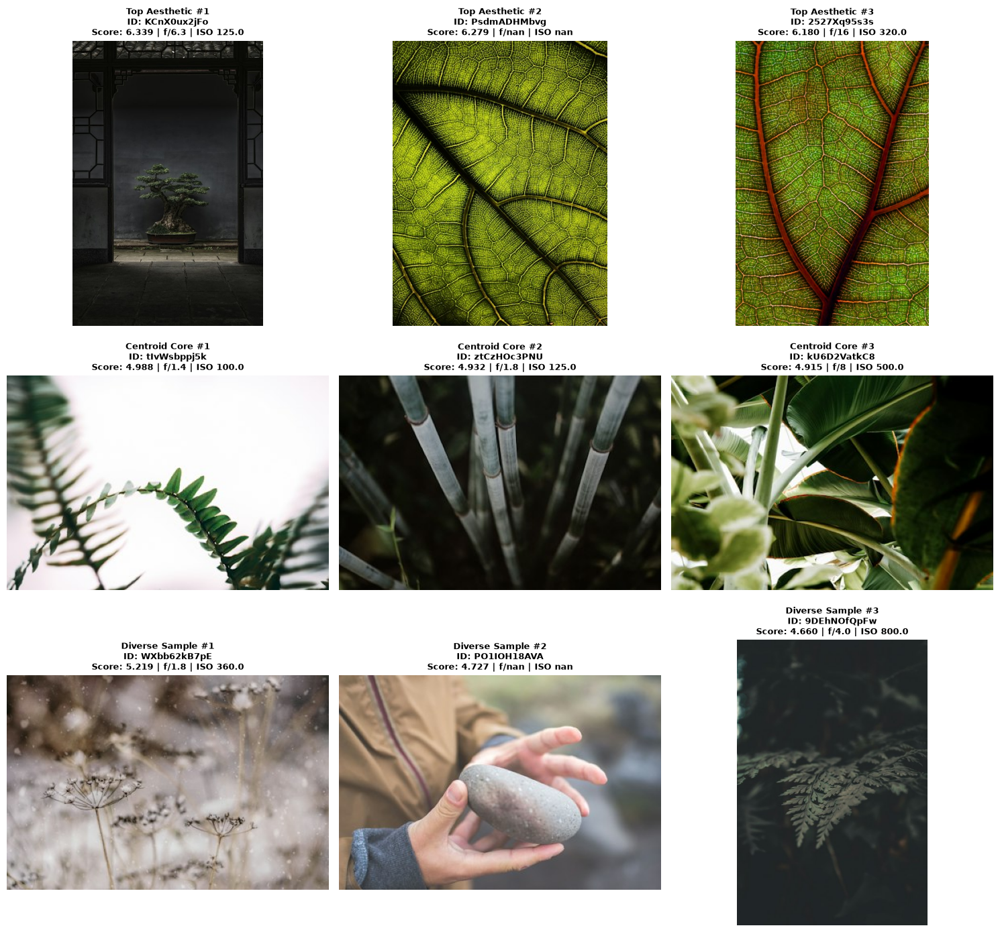

----------------------------------------------------------------------------------------------------

[CLUSTER  2] Size: 1,122 ( 4.5%) | Mean Score: 5.564 | High Aesthetic: 47.4% | Frequent Aperture: f/5.6
  Dominant Semantic Tags: outdoors, nature, desert, soil, sand, mountain, landscape, dune


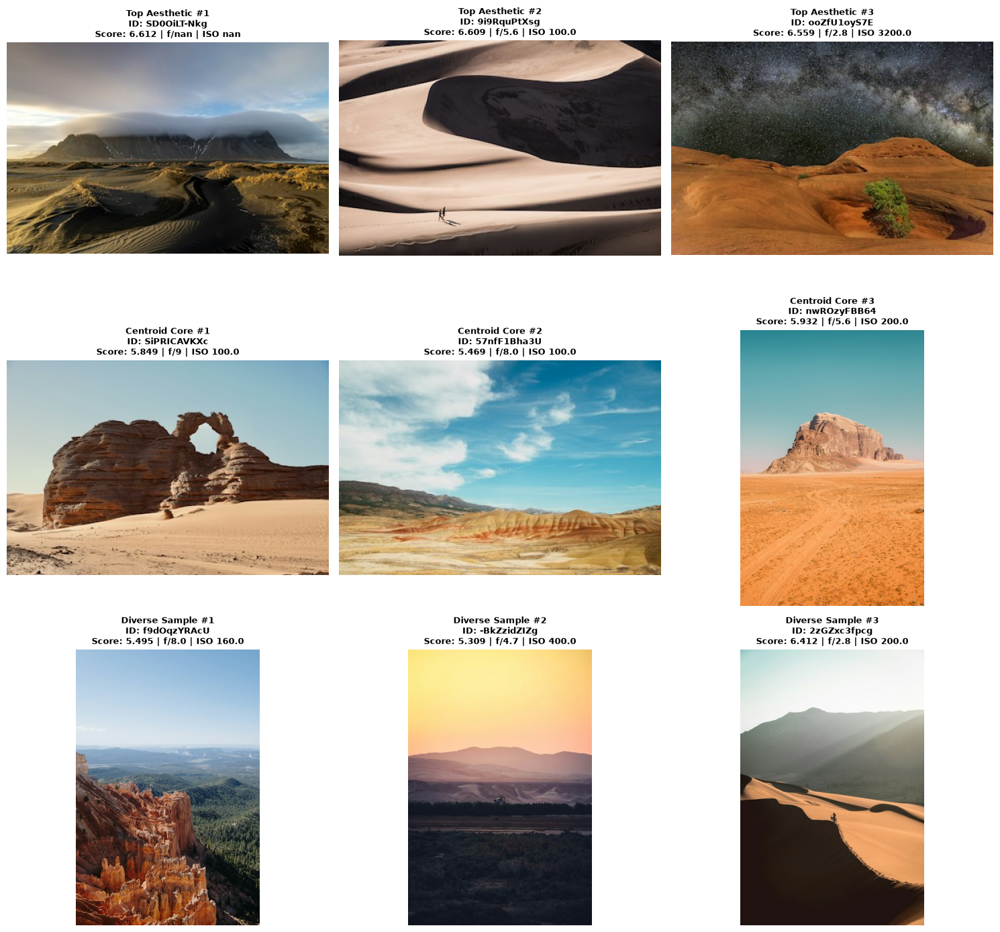

----------------------------------------------------------------------------------------------------

[CLUSTER  3] Size: 2,733 (10.9%) | Mean Score: 5.600 | High Aesthetic: 50.4% | Frequent Aperture: f/5.6
  Dominant Semantic Tags: outdoors, nature, mountain, mountain_range, grey, landscape, snow, scenery


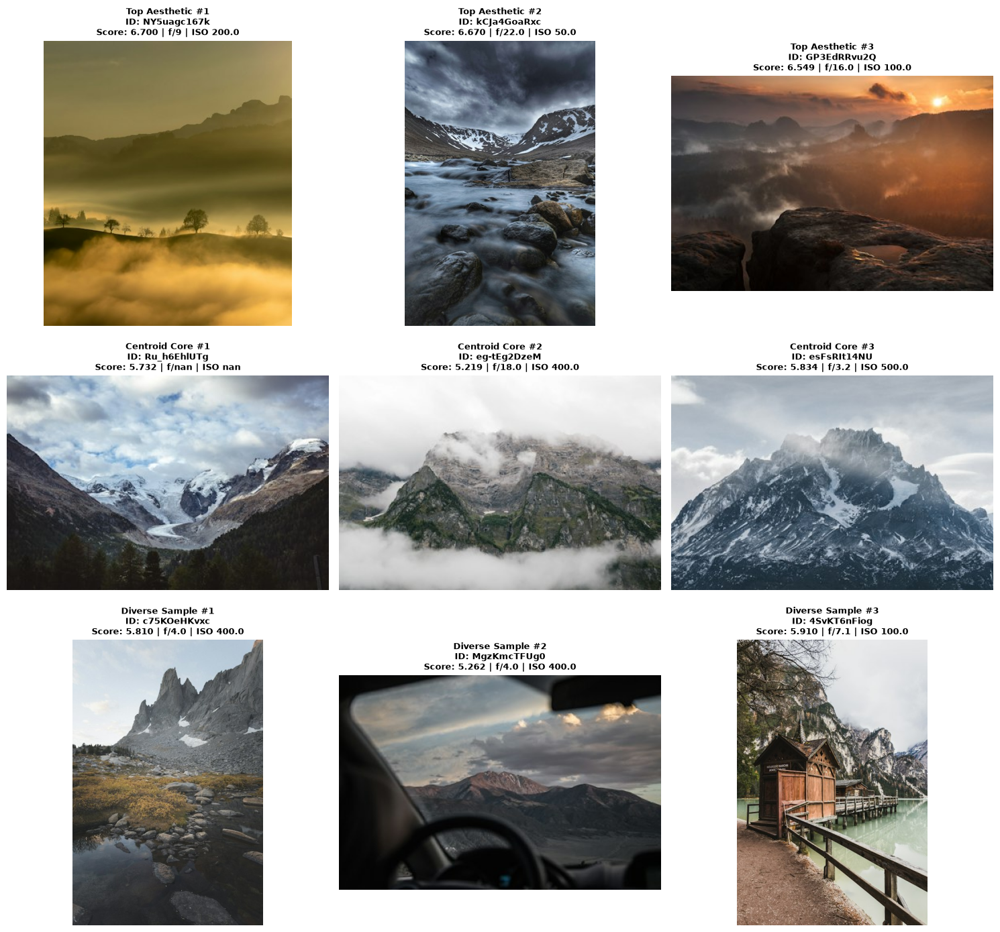

----------------------------------------------------------------------------------------------------

[CLUSTER  4] Size: 1,036 ( 4.1%) | Mean Score: 5.387 | High Aesthetic: 24.8% | Frequent Aperture: f/5.6
  Dominant Semantic Tags: mammal, animal, wildlife, grey, nature, brown, outdoors, antelope


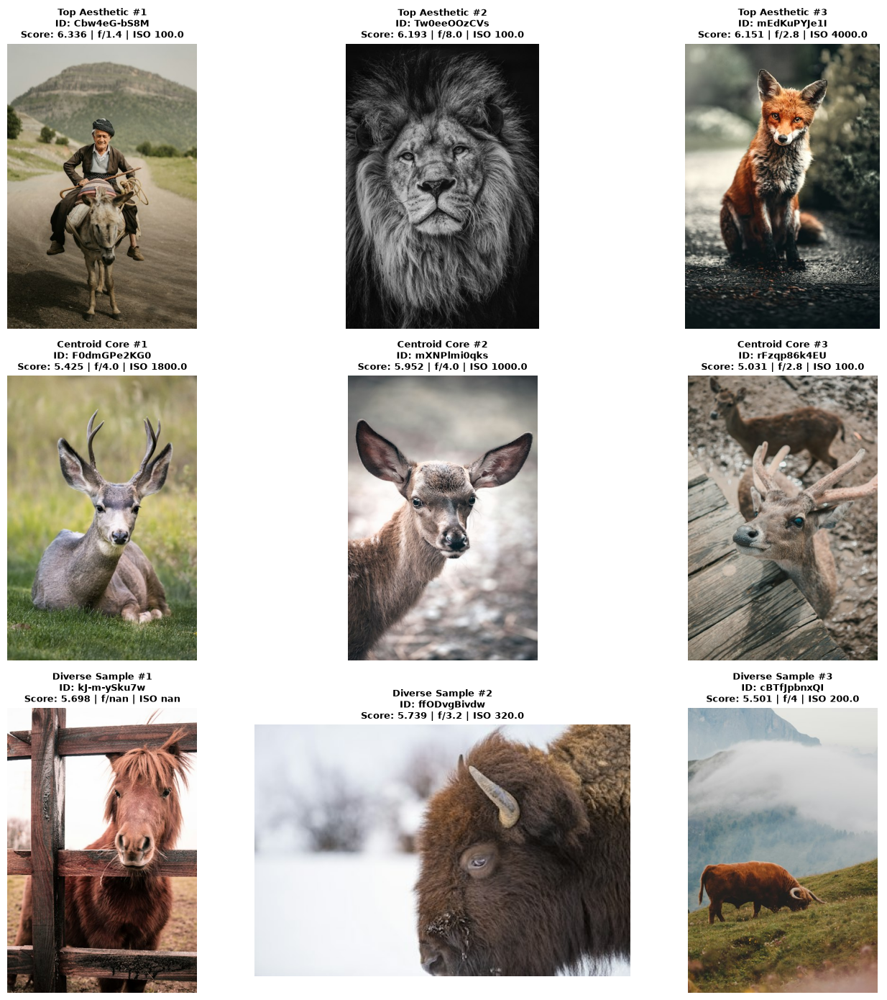

----------------------------------------------------------------------------------------------------

[CLUSTER  5] Size: 1,495 ( 6.0%) | Mean Score: 5.328 | High Aesthetic: 22.7% | Frequent Aperture: f/5.6
  Dominant Semantic Tags: nature, sky, outdoors, sunrise, red_sky, sunset, dusk, dawn


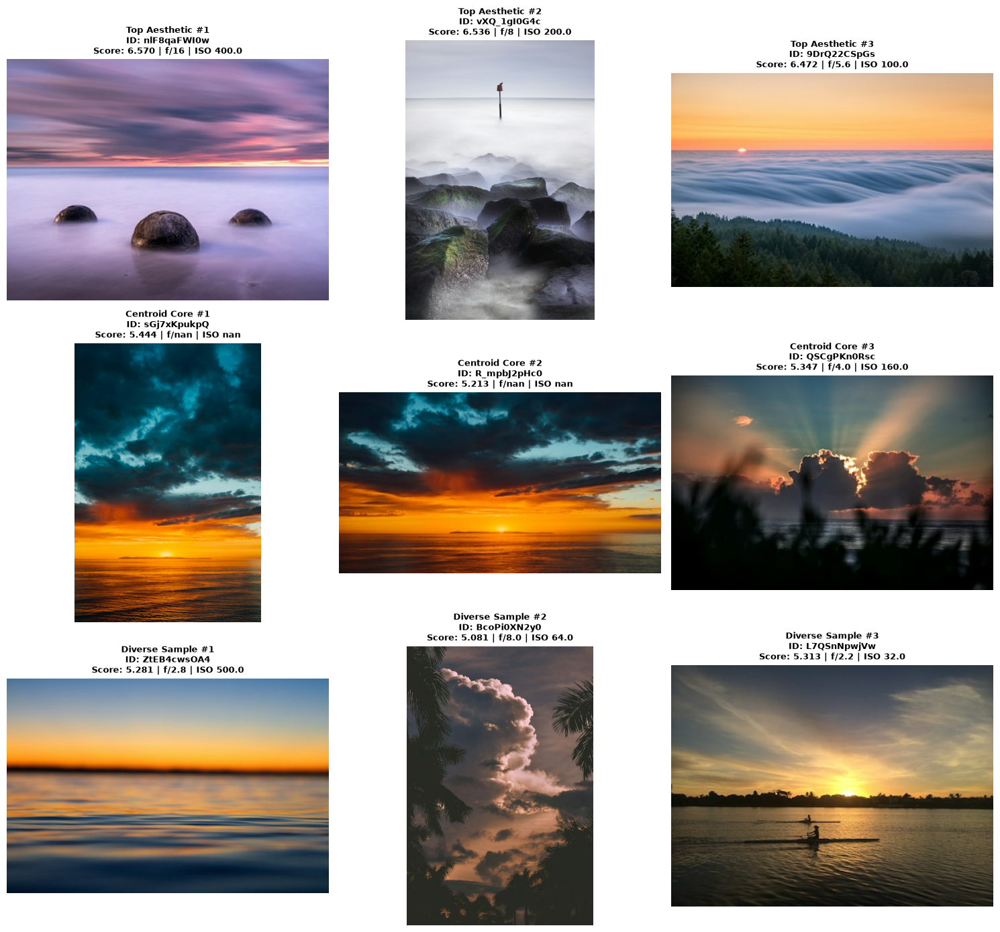

----------------------------------------------------------------------------------------------------

[CLUSTER  6] Size: 2,078 ( 8.3%) | Mean Score: 5.096 | High Aesthetic:  4.8% | Frequent Aperture: f/2.8
  Dominant Semantic Tags: plant, flower, blossom, petal, geranium, nature, rose, grey


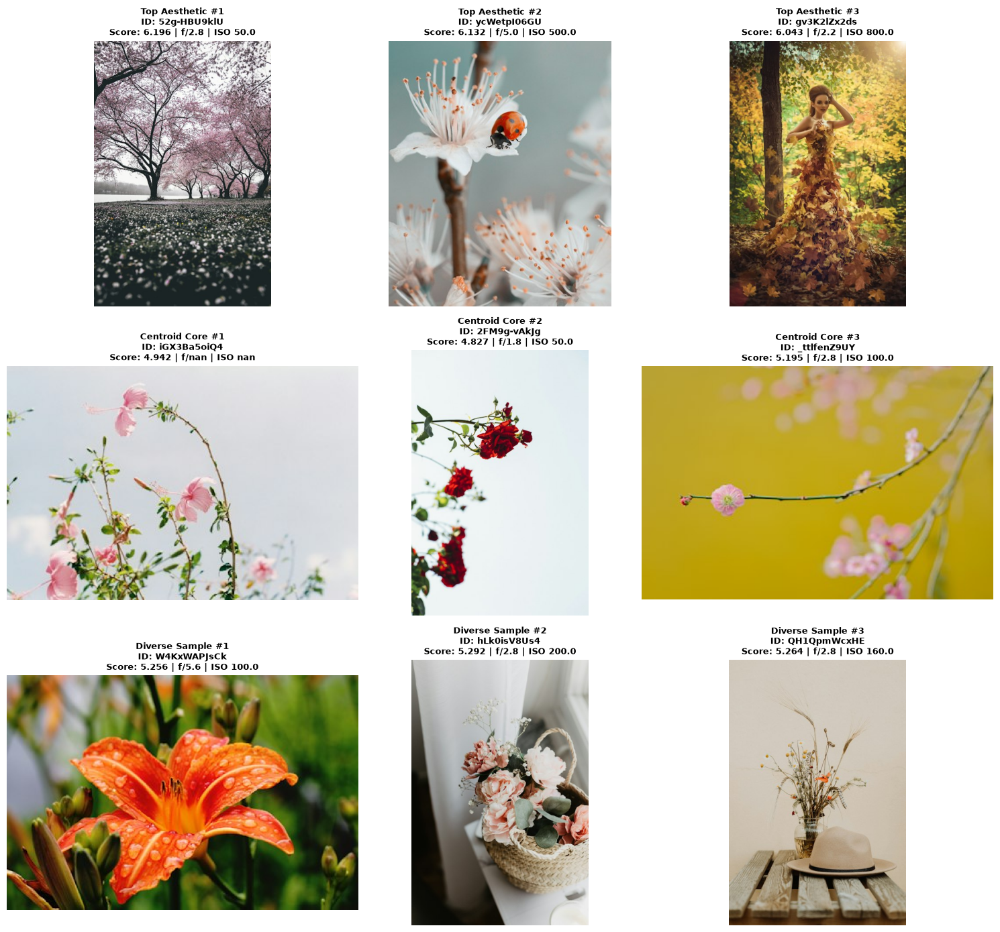

----------------------------------------------------------------------------------------------------

[CLUSTER  7] Size: 1,292 ( 5.2%) | Mean Score: 5.387 | High Aesthetic: 29.4% | Frequent Aperture: f/2.8
  Dominant Semantic Tags: building, outdoors, urban, grey, town, city, nature, architecture


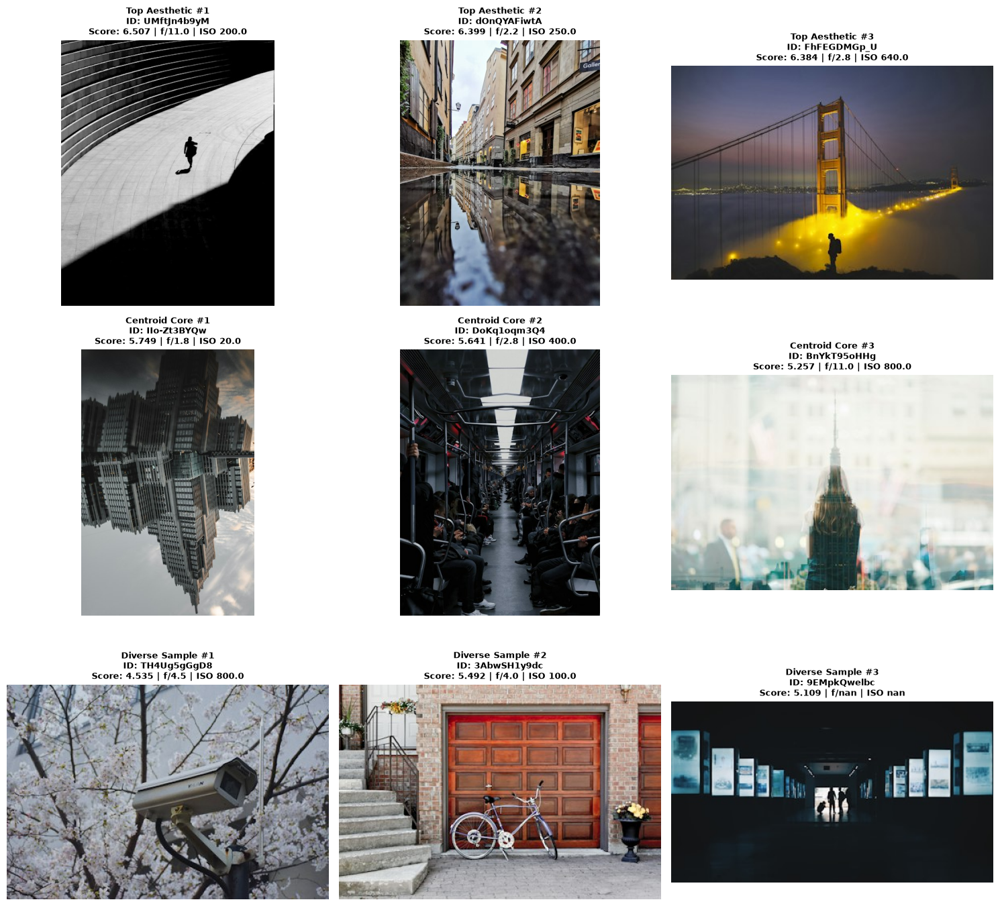

----------------------------------------------------------------------------------------------------

[CLUSTER  8] Size: 1,032 ( 4.1%) | Mean Score: 5.313 | High Aesthetic: 19.4% | Frequent Aperture: f/5.6
  Dominant Semantic Tags: animal, bird, wildlife, beak, grey, nature, plant, outdoors


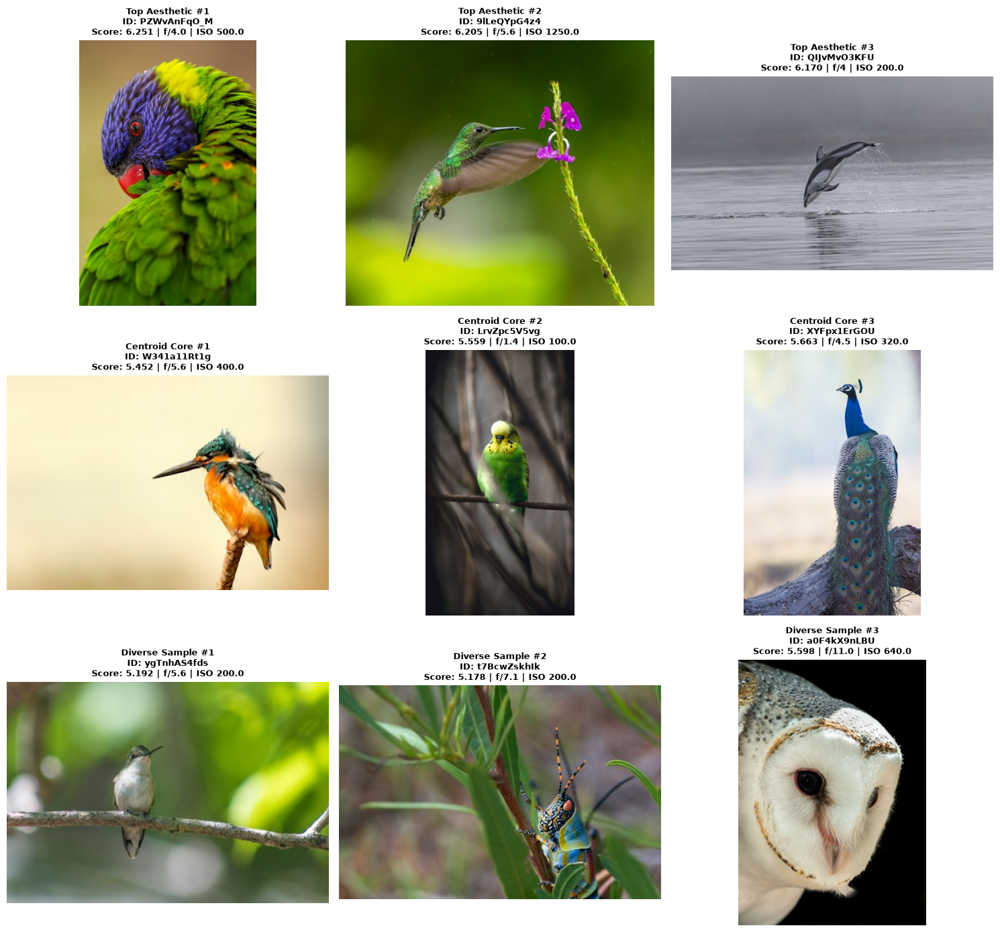

----------------------------------------------------------------------------------------------------

[CLUSTER  9] Size: 2,012 ( 8.1%) | Mean Score: 5.373 | High Aesthetic: 22.1% | Frequent Aperture: f/2.8
  Dominant Semantic Tags: nature, outdoors, plant, tree, grey, forest, land, conifer


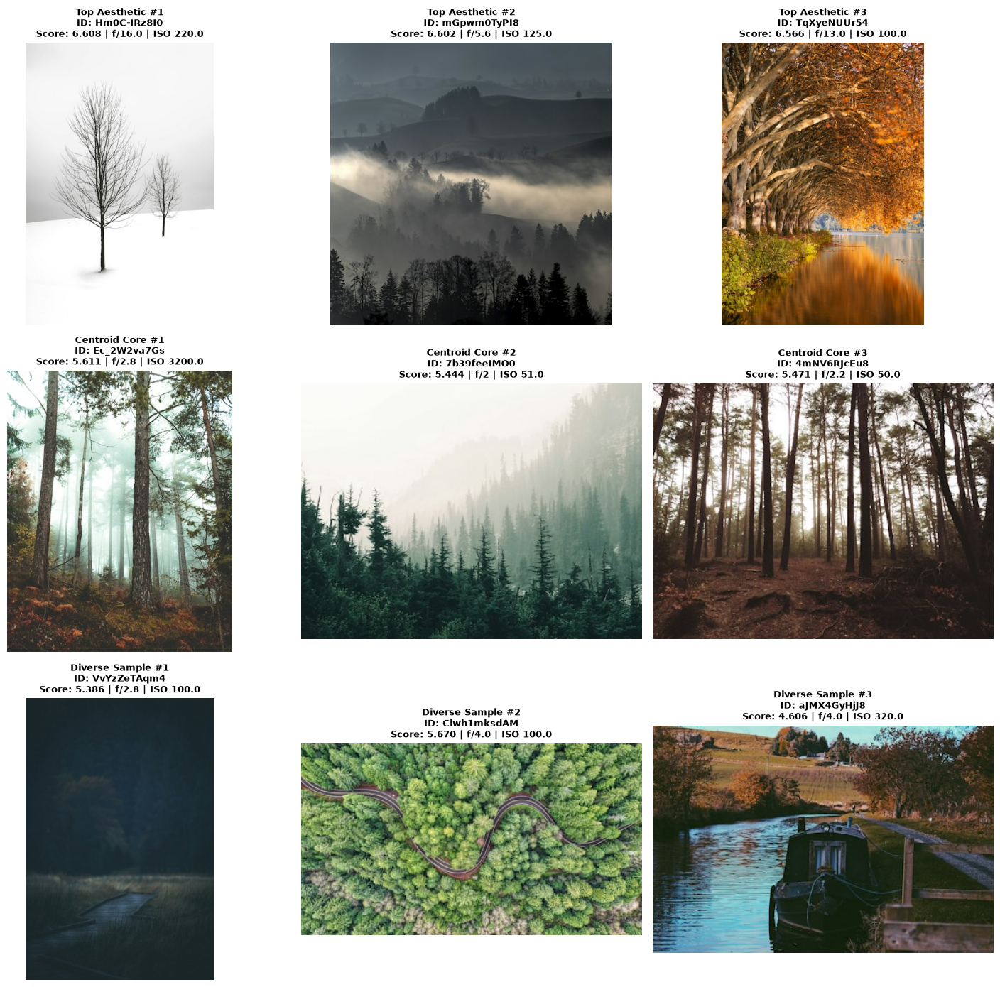

----------------------------------------------------------------------------------------------------

[CLUSTER 10] Size: 1,273 ( 5.1%) | Mean Score: 5.557 | High Aesthetic: 49.8% | Frequent Aperture: f/2.8
  Dominant Semantic Tags: outdoors, nature, night, space, astronomy, outer_space, universe, nebula


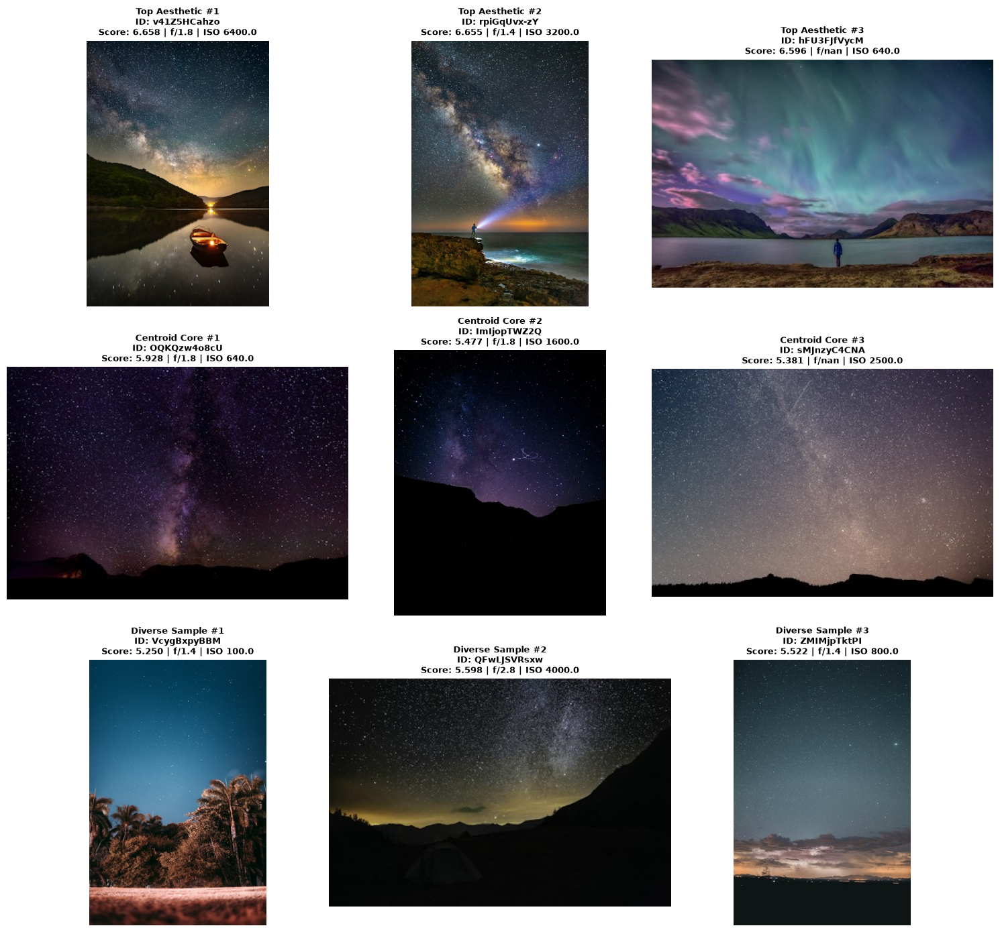

----------------------------------------------------------------------------------------------------

[CLUSTER 11] Size: 2,399 ( 9.6%) | Mean Score: 5.435 | High Aesthetic: 29.2% | Frequent Aperture: f/2.8
  Dominant Semantic Tags: outdoors, nature, water, sea, ocean, coast, beach, scenery


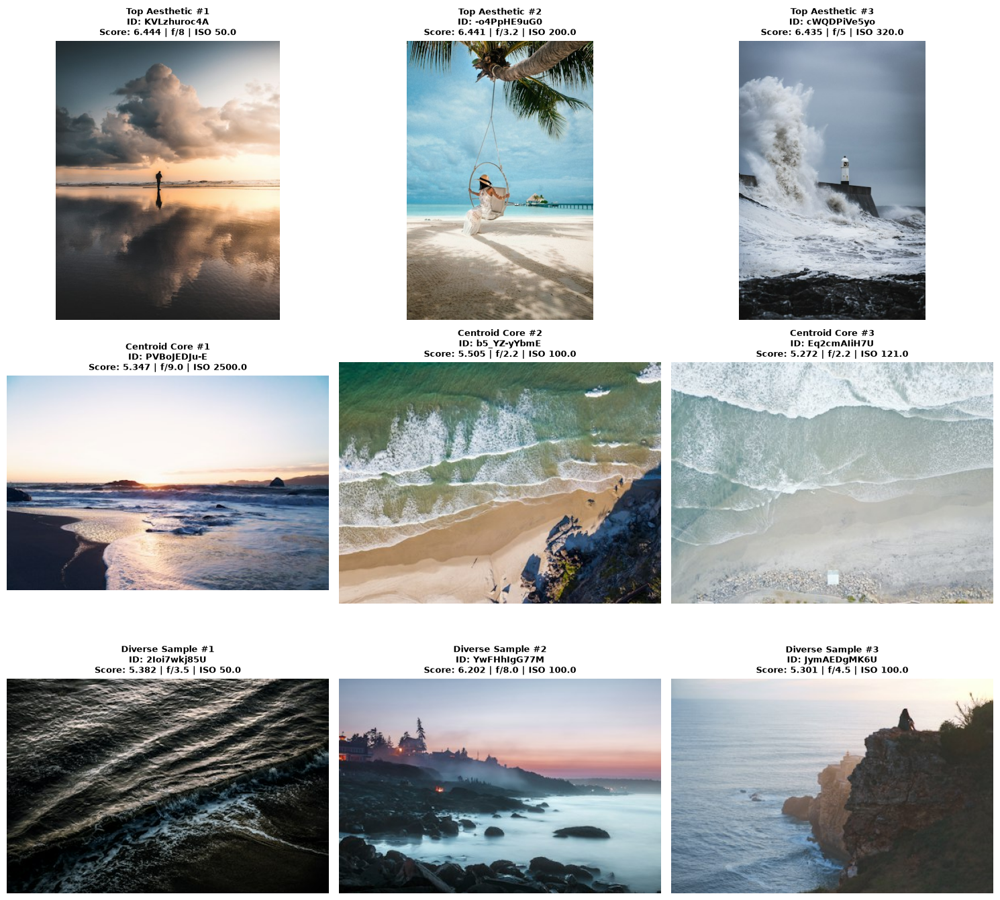

----------------------------------------------------------------------------------------------------

[CLUSTER 12] Size: 1,261 ( 5.0%) | Mean Score: 5.260 | High Aesthetic: 12.1% | Frequent Aperture: f/1.8
  Dominant Semantic Tags: mammal, pet, animal, dog, canine, grey, puppy, cat


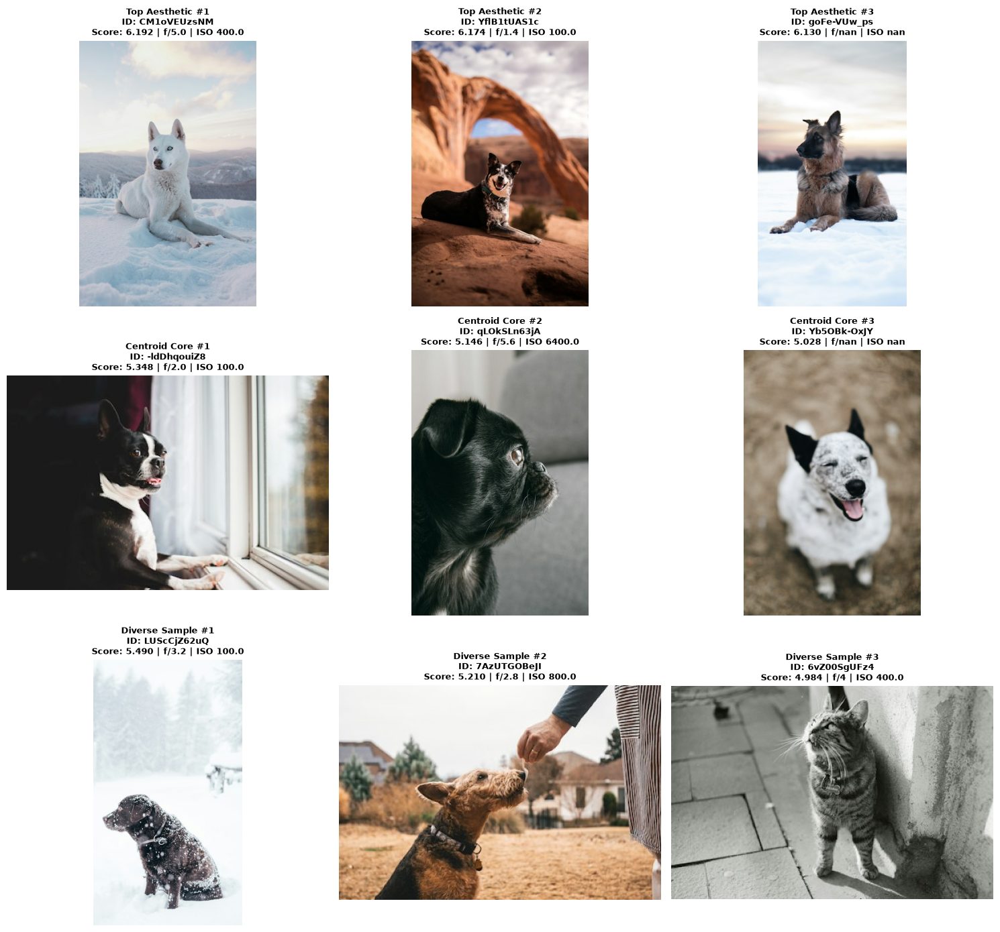

----------------------------------------------------------------------------------------------------

[CLUSTER 13] Size: 614 ( 2.5%) | Mean Score: 5.225 | High Aesthetic: 15.5% | Frequent Aperture: f/2.8
  Dominant Semantic Tags: sea_life, animal, invertebrate, water, jellyfish, sea, fish, aquatic


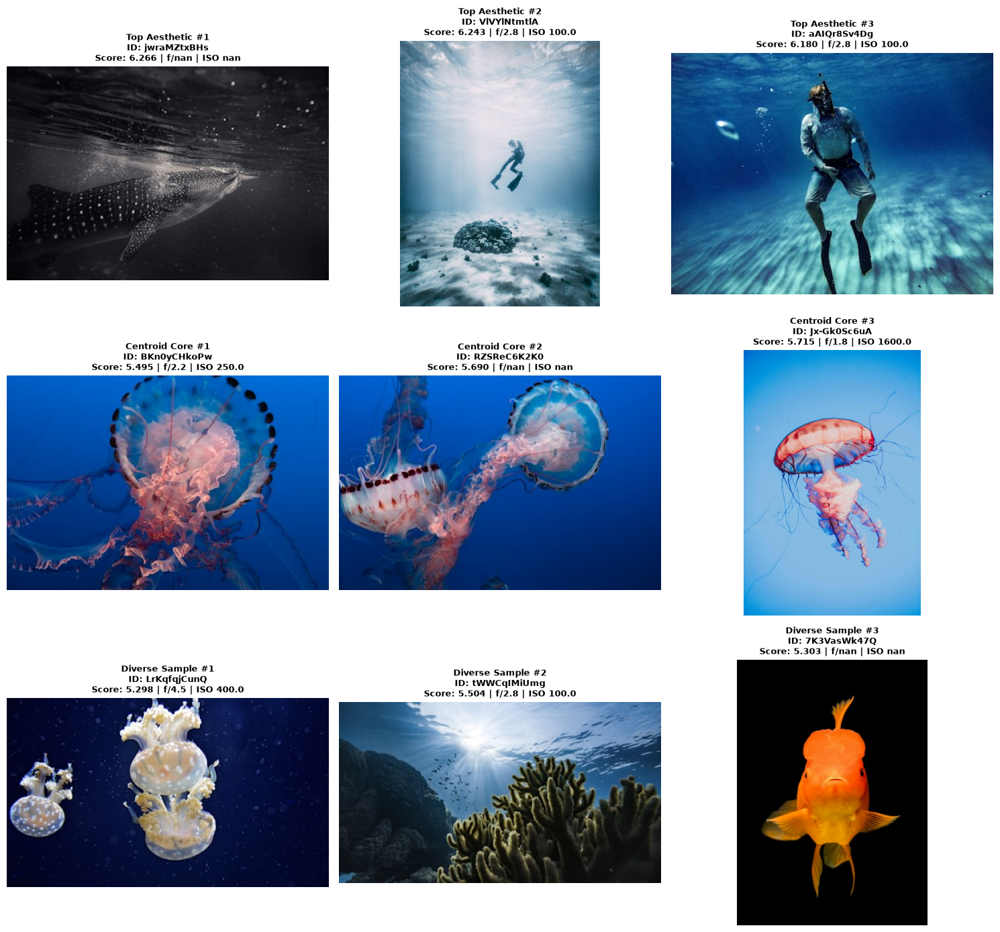

----------------------------------------------------------------------------------------------------

[CLUSTER 14] Size: 1,550 ( 6.2%) | Mean Score: 5.364 | High Aesthetic: 23.5% | Frequent Aperture: f/2.8
  Dominant Semantic Tags: person, human, clothing, outdoors, apparel, plant, nature, grey


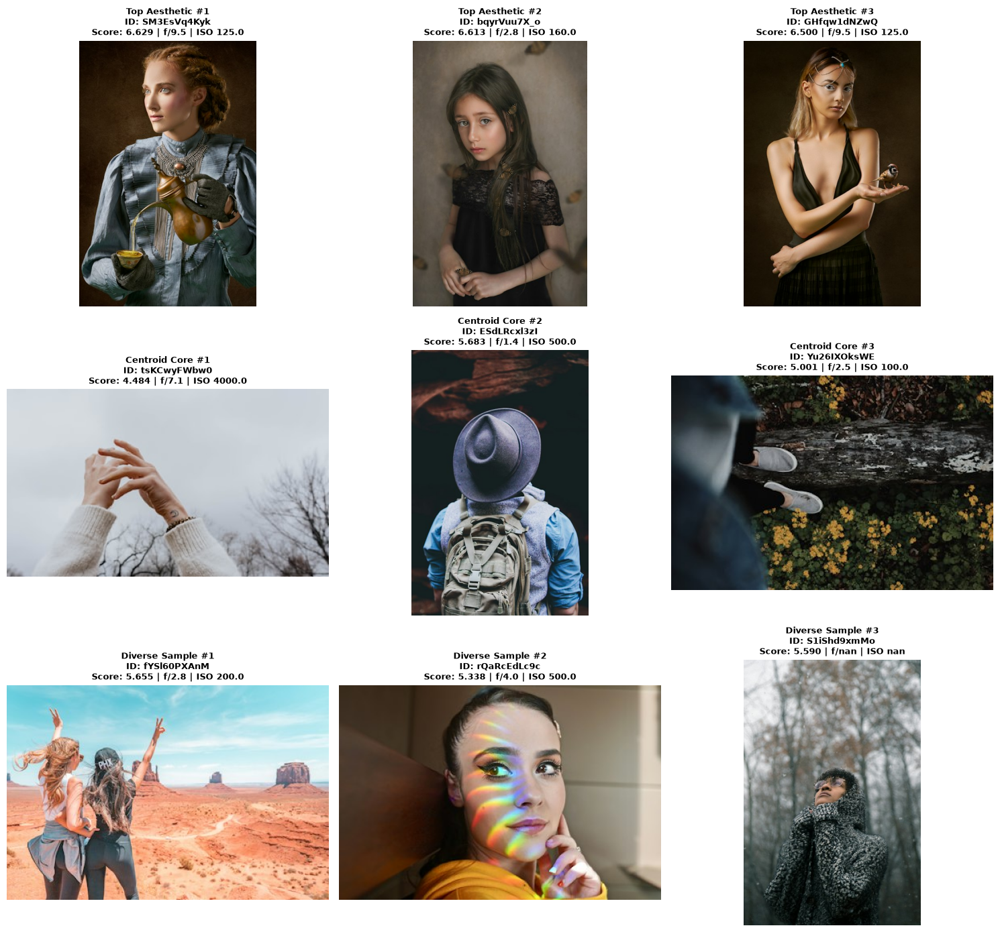

----------------------------------------------------------------------------------------------------

[CLUSTER 15] Size: 888 ( 3.6%) | Mean Score: 5.598 | High Aesthetic: 50.6% | Frequent Aperture: f/2.8
  Dominant Semantic Tags: nature, outdoors, river, water, scenery, grey, tree, landscape


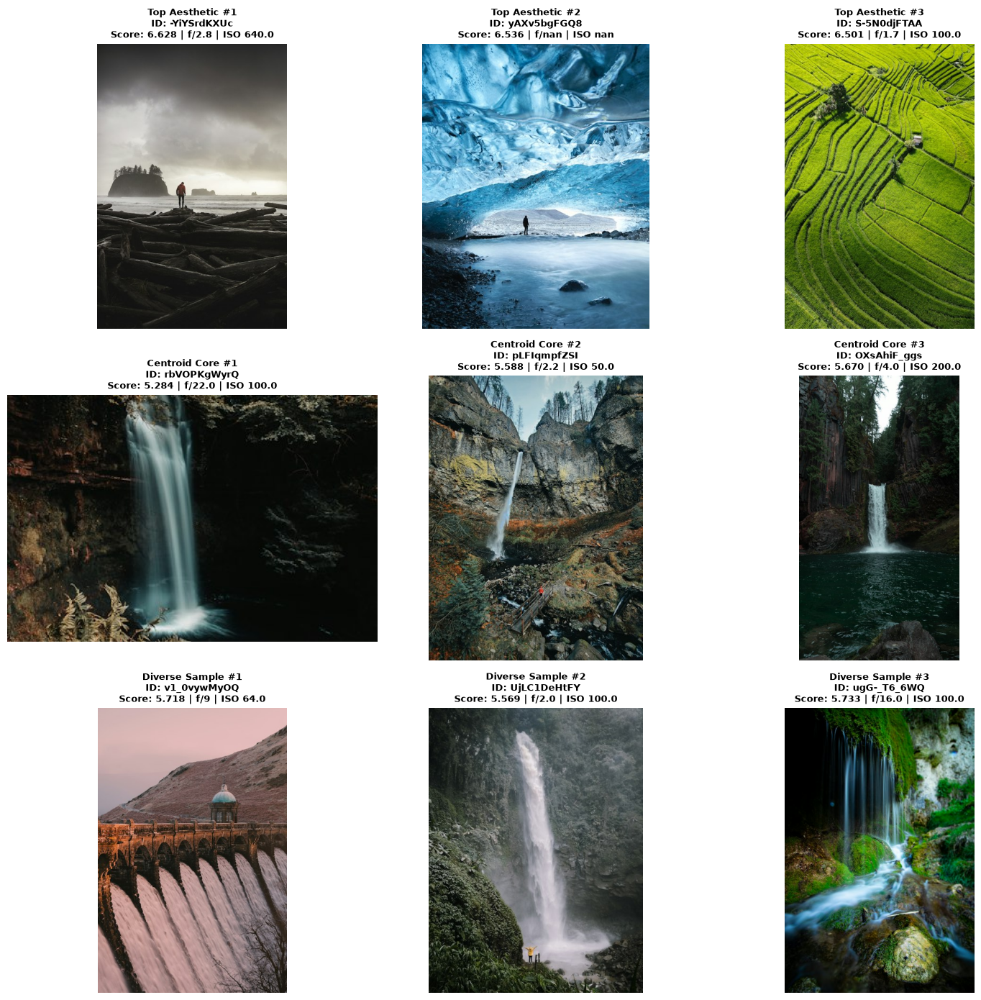

----------------------------------------------------------------------------------------------------


In [9]:
import glob
import io
from pathlib import Path
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
import requests

# 1. Ensure photo_to_tags dictionary exists
if "photo_to_tags" not in globals():
  raw_dir = Path("data/unsplash-research-dataset-lite-latest")
  kw_files = sorted(glob.glob(str(raw_dir / "keywords.*sv*"))) or sorted(
      glob.glob("data/keywords.*sv*")
  )

  if kw_files:
    df_kw = pd.concat(
        [
            pd.read_csv(f, sep="\t", header=0, low_memory=False)
            for f in kw_files
        ],
        ignore_index=True,
    )
    if "confidence" in df_kw.columns:
      df_kw = df_kw[df_kw["confidence"] >= 0.5]
    photo_to_tags = (
        df_kw.groupby("photo_id")["keyword"]
        .apply(lambda tags: [
            f"Tag_{str(t).lower().strip().replace(' ', '_')}" for t in tags[:6]
        ])
        .to_dict()
    )
  else:
    photo_to_tags = {}

session = requests.Session()
cluster_centers = final_kmeans.cluster_centers_

print("=" * 100)
print(f"3x3 VISUAL GALLERIES (9 PHOTOS PER CLUSTER) | k = {optimal_k}")
print("=" * 100)

for cid in sorted(df_photos["cluster_id"].unique()):
  c_mask = df_photos["cluster_id"] == cid
  cluster_df = df_photos[c_mask]
  cluster_size = len(cluster_df)
  pct = (cluster_size / len(df_photos)) * 100

  # Semantic Tags
  cluster_tags = []
  for pid in cluster_df["photo_id"]:
    if pid in photo_to_tags:
      cluster_tags.extend(photo_to_tags[pid])

  if cluster_tags:
    tag_counts = pd.Series(cluster_tags).value_counts()
    clean_top_tags = [
        t.replace("Tag_", "") for t in tag_counts.head(8).index.tolist()
    ]
    tag_str = ", ".join(clean_top_tags)
  else:
    tag_str = "None available"

  # Metrics
  mean_score = cluster_df["predicted_aesthetic_score"].mean()
  high_ratio = (cluster_df["aesthetic_bin"] == "High_Aesthetic").mean() * 100

  dom_aperture = cluster_df["exif_aperture_value"].dropna().astype(str).mode()
  aperture_mode = dom_aperture.iloc[0] if not dom_aperture.empty else "N/A"

  # -------------------------------------------------------------------------
  # Select 9 Photos in a 3x3 Matrix:
  #   Row 1: Top 3 Aesthetic Scorers (Aesthetic Leaders)
  #   Row 2: 3 Closest to Centroid (Geometric Core / Medoids)
  #   Row 3: 3 Diverse Random Samples (Cluster Variance)
  # -------------------------------------------------------------------------
  cluster_pca_indices = np.where(c_mask)[0]
  cluster_pca_vecs = X_pca50[c_mask]
  center_k = cluster_centers[cid]

  # Row 1: Top 3 Aesthetic
  top_3_aesthetic = cluster_df.sort_values(
      by="predicted_aesthetic_score", ascending=False
  ).head(3)

  # Row 2: Top 3 Medoids (nearest Euclidean distance to cluster centroid)
  dists = np.linalg.norm(cluster_pca_vecs - center_k, axis=1)
  medoid_local_indices = np.argsort(dists)[:3]
  top_3_medoids = df_photos.iloc[cluster_pca_indices[medoid_local_indices]]

  # Row 3: 3 Random / General Samples (excluding already selected IDs)
  selected_pids = set(top_3_aesthetic["photo_id"]).union(
      set(top_3_medoids["photo_id"])
  )
  remaining_df = cluster_df[~cluster_df["photo_id"].isin(selected_pids)]
  diverse_samples = (
      remaining_df.sample(n=min(3, len(remaining_df)), random_state=42)
      if len(remaining_df) >= 3
      else remaining_df
  )

  gallery_items = []
  for rank, (_, row) in enumerate(top_3_aesthetic.iterrows(), start=1):
    gallery_items.append((f"Top Aesthetic #{rank}", row))
  for rank, (_, row) in enumerate(top_3_medoids.iterrows(), start=1):
    gallery_items.append((f"Centroid Core #{rank}", row))
  for rank, (_, row) in enumerate(diverse_samples.iterrows(), start=1):
    gallery_items.append((f"Diverse Sample #{rank}", row))

  print(
      f"\n[CLUSTER {cid:2d}] Size: {cluster_size:,} ({pct:4.1f}%) | Mean Score:"
      f" {mean_score:.3f} | High Aesthetic: {high_ratio:4.1f}% | Frequent"
      f" Aperture: f/{aperture_mode}"
  )
  print(f"  Dominant Semantic Tags: {tag_str}")

  # Render 3x3 Subplot Grid
  fig, axes = plt.subplots(3, 3, figsize=(15, 14))
  axes = axes.flatten()

  for ax, (label_title, row) in zip(axes, gallery_items):
    url = str(row.get("photo_image_url", ""))
    fetch_url = (
        f"{url}?w=400&q=80" if "?" not in url else f"{url}&w=400&q=80"
    )

    img = None
    if url:
      try:
        res = session.get(fetch_url, timeout=10)
        if res.status_code == 200:
          img = Image.open(io.BytesIO(res.content))
      except Exception:
        pass

    if img:
      ax.imshow(img)
      ax.axis("off")
      score_val = row.get("predicted_aesthetic_score", 0.0)
      ap_val = row.get("exif_aperture_value", "N/A")
      iso_val = row.get("exif_iso", "N/A")
      ax.set_title(
          f"{label_title}\nID: {row['photo_id']}\nScore: {score_val:.3f} |"
          f" f/{ap_val} | ISO {iso_val}",
          fontsize=9,
          fontweight="semibold",
      )
    else:
      ax.text(0.5, 0.5, "Image load failed", ha="center", va="center")
      ax.axis("off")

  # Turn off unused subplots if cluster has fewer than 9 photos
  for extra_ax in axes[len(gallery_items) :]:
    extra_ax.axis("off")

  plt.tight_layout()
  plt.show()
  print("-" * 100)

# Section 2.2: Clustering on Technical EXIF Metadata & Semantic Keyword Tags

### Methodology & Representation
Rather than clustering in CLIP visual embedding space, we cluster directly on the descriptive metadata:
1. **Semantic Representation (TF-IDF + TruncatedSVD):** Unsplash user tags are aggregated per photo and transformed into a TF-IDF representation (filtering vocabulary to terms with document frequency $\ge 10$). We reduce the sparse keyword matrix to 30 latent semantic dimensions using TruncatedSVD.
2. **Technical Camera Parameters (Standardized EXIF):**
   * $\log_2(\text{ISO})$: Linearizes exposure stops.
   * Aperture ($f\text{-number}$): Continuous optical depth control.
   * Focal Length: Field-of-view proxy.
   * Camera Make: One-hot encoded indicator vector.
3. **Composite Feature Space:** We concatenate the normalized latent semantic space and scaled EXIF features into matrix $X_{\text{meta}}$, re-evaluating optimal cluster granularity via the **Davies-Bouldin Index**.

In [11]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import davies_bouldin_score
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# 1. Prepare Semantic Tag Documents
# -----------------------------------------------------------------------------
# Combine keywords per photo into a space-separated document string
df_photos["tag_text"] = df_photos["photo_id"].map(
    lambda pid: " ".join(photo_to_tags.get(pid, [])).replace("Tag_", "")
)

# Build TF-IDF matrix (min_df=10 removes rare noise)
tfidf = TfidfVectorizer(max_features=2000, min_df=10)
X_tfidf = tfidf.fit_transform(df_photos["tag_text"])

# Reduce TF-IDF to 30 latent semantic dimensions via TruncatedSVD
svd = TruncatedSVD(n_components=30, random_state=42)
X_tags_latent = svd.fit_transform(X_tfidf)
# L2-normalize latent semantic vectors
X_tags_norm = X_tags_latent / (np.linalg.norm(X_tags_latent, axis=1, keepdims=True) + 1e-7)

print(f"Constructed latent tag representation: {X_tags_norm.shape}")

# -----------------------------------------------------------------------------
# 2. Extract & Encode EXIF Hardware Metadata (Safe Numeric Coercion)
# -----------------------------------------------------------------------------
# 1. ISO: coerce to numeric first, then compute median
iso_numeric = pd.to_numeric(df_photos["exif_iso"], errors="coerce")
default_iso = float(iso_numeric.median()) if not np.isnan(iso_numeric.median()) else 200.0
iso_clean = iso_numeric.fillna(default_iso)
iso_log = np.log2(np.clip(iso_clean, 50.0, 102400.0))

# 2. Aperture: coerce to numeric first, then compute median
aperture_numeric = pd.to_numeric(df_photos["exif_aperture_value"], errors="coerce")
default_aperture = float(aperture_numeric.median()) if not np.isnan(aperture_numeric.median()) else 4.0
aperture_clean = aperture_numeric.fillna(default_aperture)
aperture_clamped = np.clip(aperture_clean, 1.0, 32.0)

# 3. Focal Length: coerce to numeric first, then compute median
focal_numeric = pd.to_numeric(df_photos["exif_focal_length"], errors="coerce")
default_focal = float(focal_numeric.median()) if not np.isnan(focal_numeric.median()) else 50.0
focal_clean = focal_numeric.fillna(default_focal)
focal_clamped = np.clip(focal_clean, 10.0, 600.0)

# Combine continuous optical features and scale
X_cont = np.column_stack([iso_log, aperture_clamped, focal_clamped])
scaler = StandardScaler()
X_cont_scaled = scaler.fit_transform(X_cont)

# Categorical Camera Make (top brands + 'Other')
top_makes = ["Canon", "Nikon", "Sony", "Fujifilm", "Apple"]
make_series = df_photos["exif_camera_make"].astype(str).str.strip().str.capitalize()
make_clean = make_series.apply(lambda m: m if m in top_makes else "Other").to_frame(name="make")

ohe = OneHotEncoder(sparse_output=False)
X_make_ohe = ohe.fit_transform(make_clean)

# -----------------------------------------------------------------------------
# 3. Concatenate into Joint Metadata Feature Space
# -----------------------------------------------------------------------------
WEIGHT_SEMANTIC = 1.0
WEIGHT_EXIF = 0.8

X_exif_all = np.hstack([X_cont_scaled, X_make_ohe])
X_meta = np.hstack([X_tags_norm * WEIGHT_SEMANTIC, X_exif_all * WEIGHT_EXIF])

print(f"Final Metadata Feature Space Shape: {X_meta.shape} (30 SVD Tags + {X_exif_all.shape[1]} EXIF features)")

Constructed latent tag representation: (24993, 30)
Final Metadata Feature Space Shape: (24993, 39) (30 SVD Tags + 9 EXIF features)


k =  6 | Davies-Bouldin: 1.8188
k =  8 | Davies-Bouldin: 1.8250
k = 10 | Davies-Bouldin: 1.9271
k = 12 | Davies-Bouldin: 1.9506
k = 16 | Davies-Bouldin: 2.0903
k = 20 | Davies-Bouldin: 1.9774

Optimal metadata clusters (minimizing DB Index): k = 6


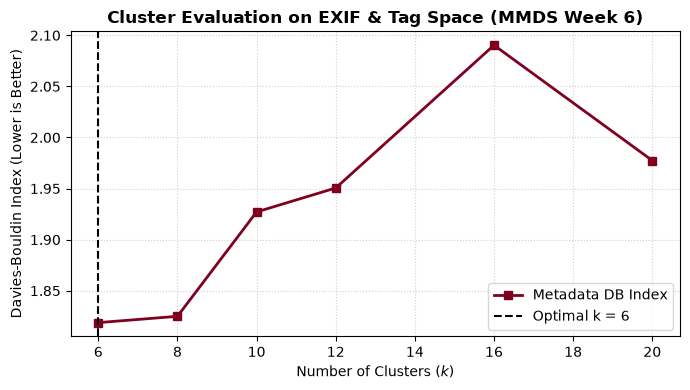

In [12]:
# -----------------------------------------------------------------------------
# 1. Sweep k Candidates using Davies-Bouldin Index
# -----------------------------------------------------------------------------
k_candidates = [6, 8, 10, 12, 16, 20]
db_meta_scores = []

for k in k_candidates:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_meta)
    db = davies_bouldin_score(X_meta, labels)
    db_meta_scores.append(db)
    print(f"k = {k:2d} | Davies-Bouldin: {db:.4f}")

optimal_k_meta = k_candidates[np.argmin(db_meta_scores)]
print(f"\nOptimal metadata clusters (minimizing DB Index): k = {optimal_k_meta}")

# Fit final optimal model
kmeans_meta = KMeans(n_clusters=optimal_k_meta, n_init=10, random_state=42)
df_photos["meta_cluster_id"] = kmeans_meta.fit_predict(X_meta)

# Plot Davies-Bouldin curve
plt.figure(figsize=(7, 4))
plt.plot(k_candidates, db_meta_scores, marker="s", color="#800020", linewidth=2, label="Metadata DB Index")
plt.axvline(optimal_k_meta, color="black", linestyle="--", label=f"Optimal k = {optimal_k_meta}")
plt.xlabel("Number of Clusters ($k$)")
plt.ylabel("Davies-Bouldin Index (Lower is Better)")
plt.title("Cluster Evaluation on EXIF & Tag Space (MMDS Week 6)", fontweight="bold")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

EXIF + TAG DRIVEN CLUSTERS (9 PHOTOS PER CLUSTER) | k = 6

[METADATA CLUSTER  0] Size: 3,282 (13.1%) | Mean Score: 5.425 | High Aesthetic: 32.2%
  Dominant Hardware Profile : Make: Canon | Median Aperture: f/9.0 | Median ISO: 125
  Top Semantic Tags         : outdoors, nature, grey, landscape, scenery, plant


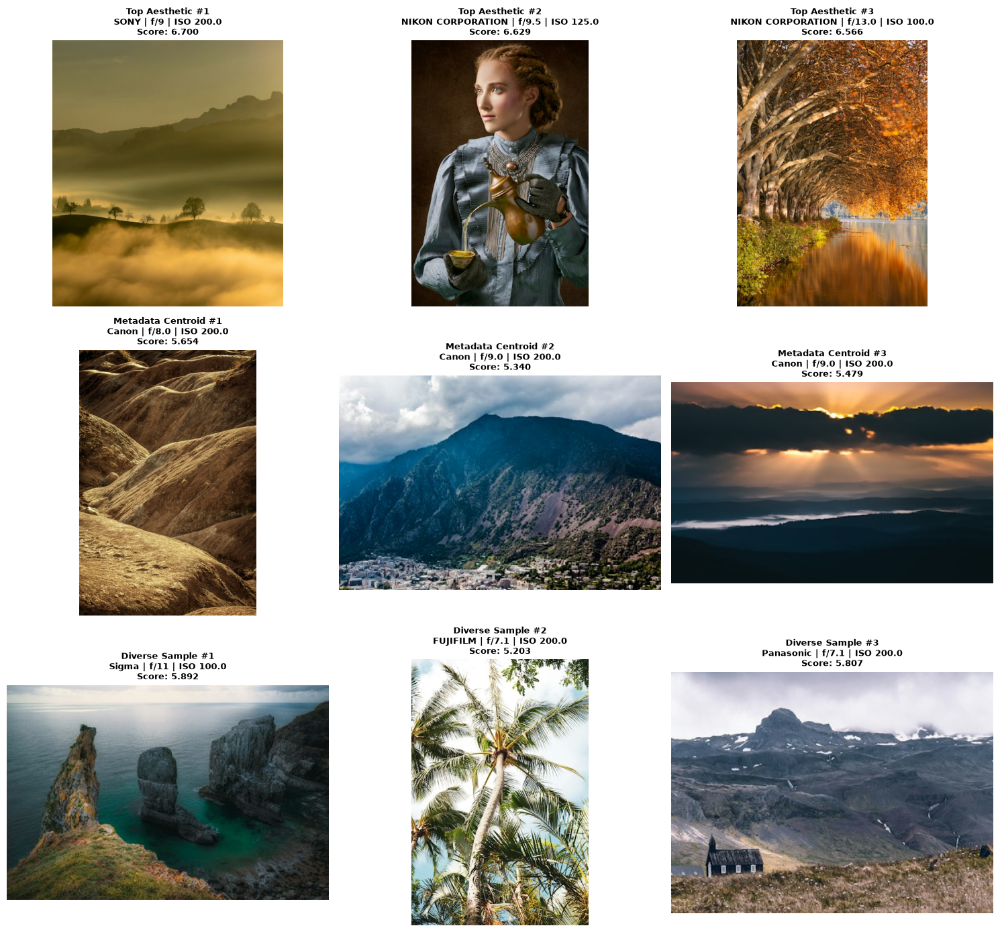

---------------------------------------------------------------------------------------------------------

[METADATA CLUSTER  1] Size: 7,628 (30.5%) | Mean Score: 5.324 | High Aesthetic: 24.3%
  Dominant Hardware Profile : Make: NIKON CORPORATION | Median Aperture: f/2.8 | Median ISO: 100
  Top Semantic Tags         : nature, outdoors, plant, grey, animal, tree


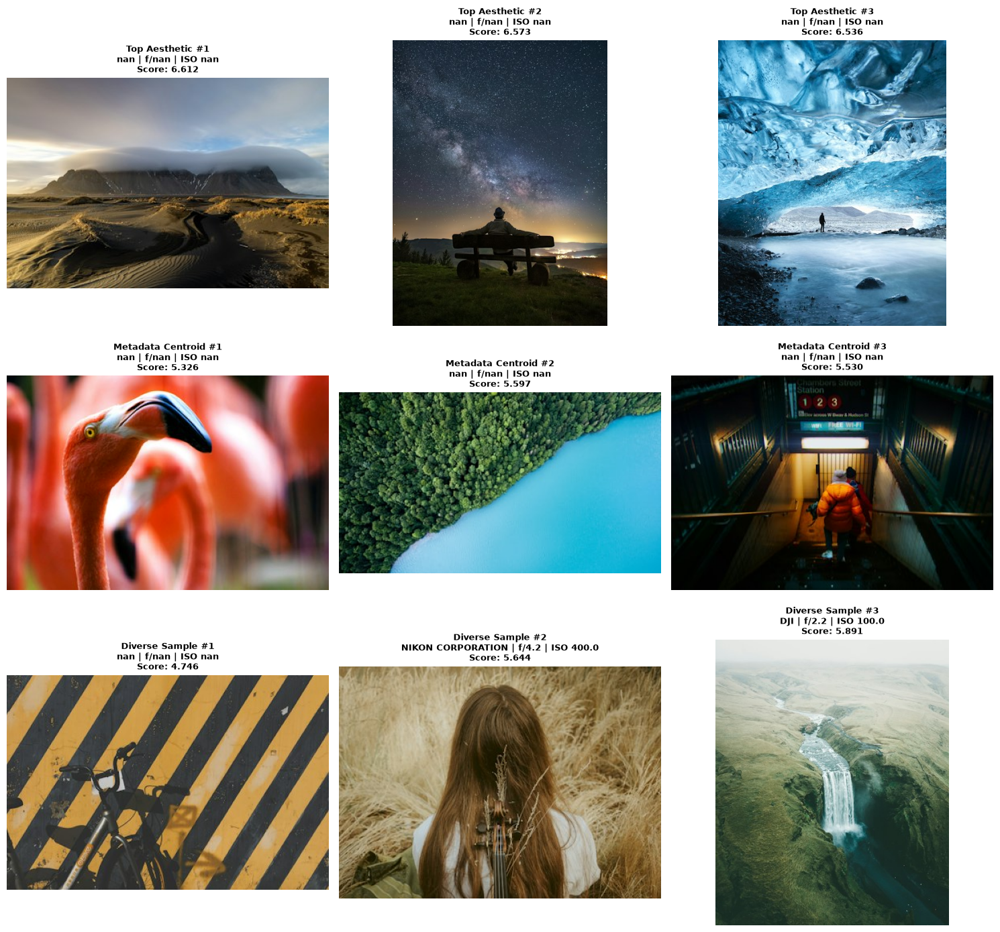

---------------------------------------------------------------------------------------------------------

[METADATA CLUSTER  2] Size: 4,266 (17.1%) | Mean Score: 5.340 | High Aesthetic: 26.2%
  Dominant Hardware Profile : Make: Canon | Median Aperture: f/3.5 | Median ISO: 1000
  Top Semantic Tags         : nature, grey, outdoors, plant, animal, sky


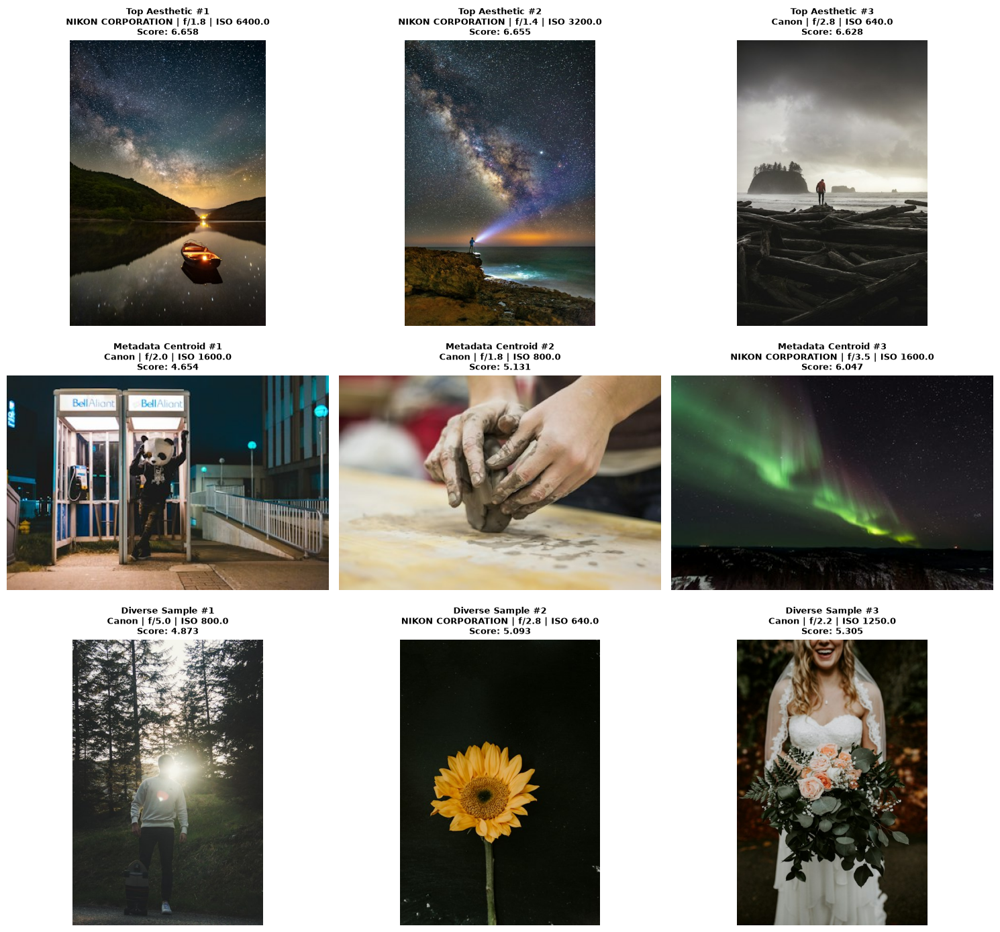

---------------------------------------------------------------------------------------------------------

[METADATA CLUSTER  3] Size: 7,951 (31.8%) | Mean Score: 5.310 | High Aesthetic: 20.9%
  Dominant Hardware Profile : Make: Canon | Median Aperture: f/2.8 | Median ISO: 100
  Top Semantic Tags         : nature, outdoors, plant, grey, animal, tree


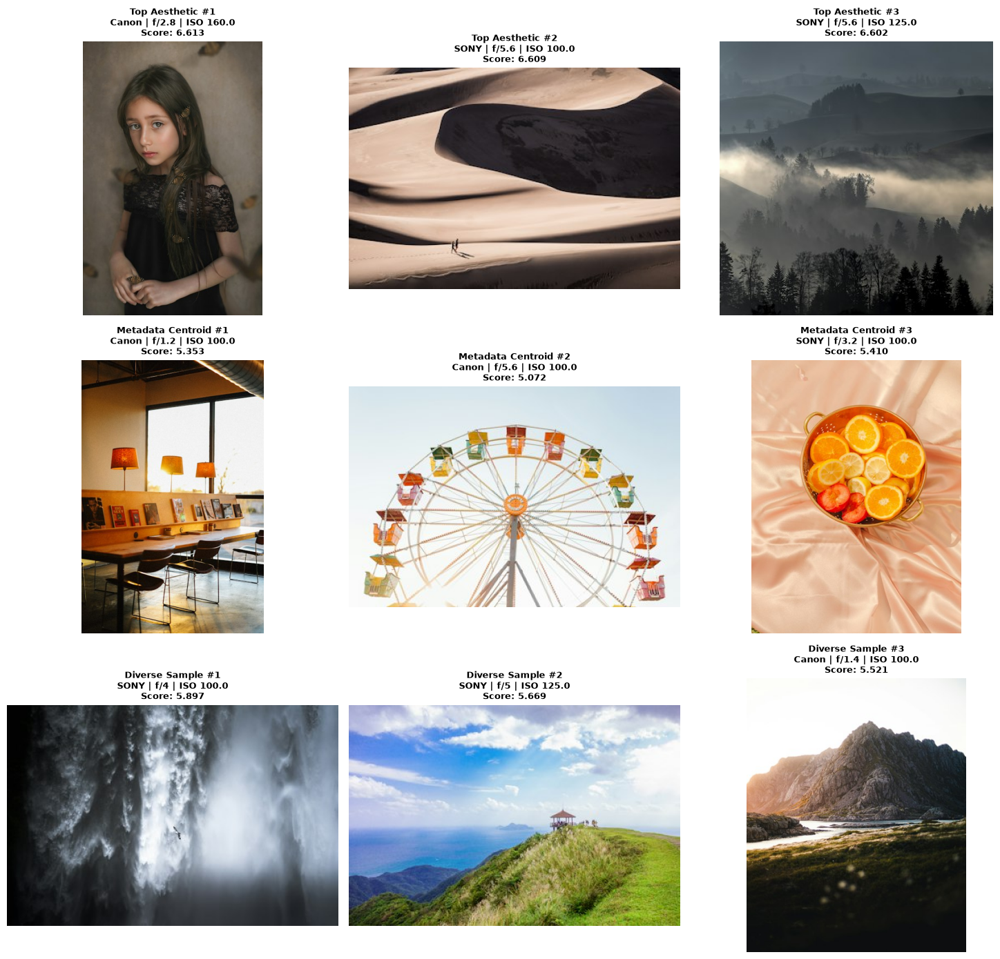

---------------------------------------------------------------------------------------------------------

[METADATA CLUSTER  4] Size: 780 ( 3.1%) | Mean Score: 5.519 | High Aesthetic: 43.8%
  Dominant Hardware Profile : Make: Canon | Median Aperture: f/16.0 | Median ISO: 125
  Top Semantic Tags         : outdoors, nature, grey, landscape, plant, sky


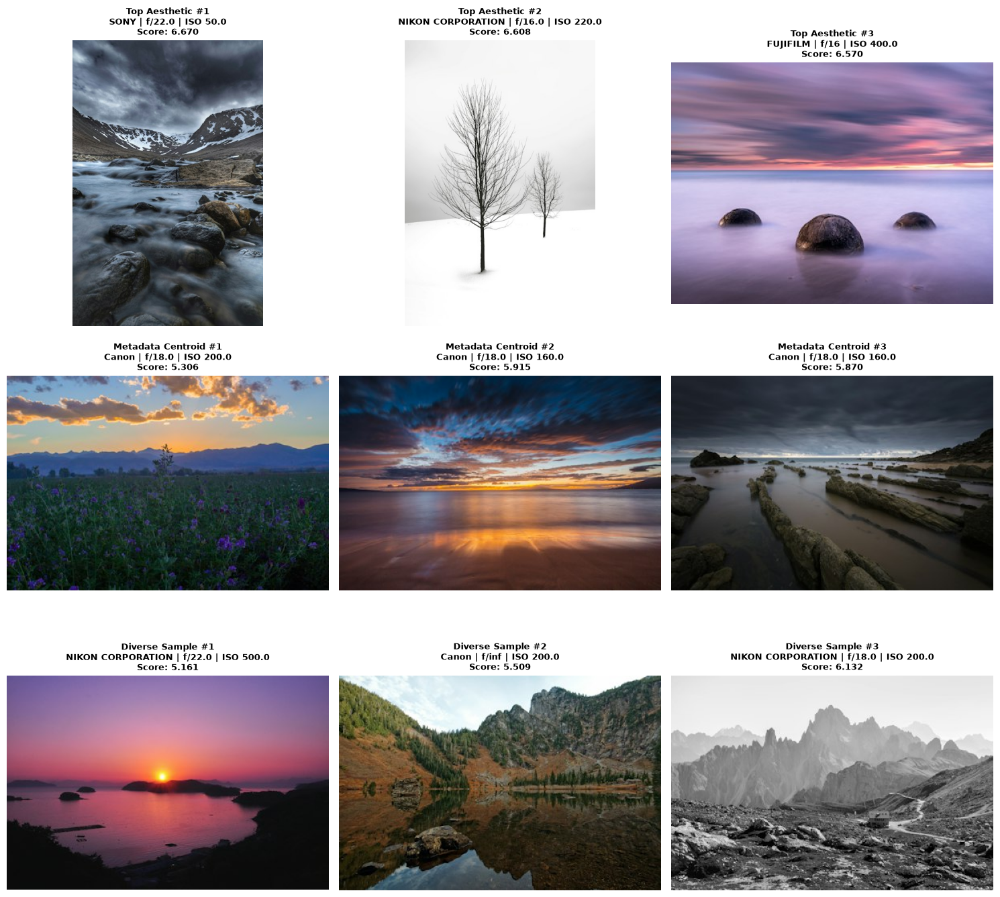

---------------------------------------------------------------------------------------------------------

[METADATA CLUSTER  5] Size: 1,086 ( 4.3%) | Mean Score: 5.290 | High Aesthetic: 19.9%
  Dominant Hardware Profile : Make: Canon | Median Aperture: f/5.6 | Median ISO: 400
  Top Semantic Tags         : animal, nature, grey, wildlife, outdoors, bird


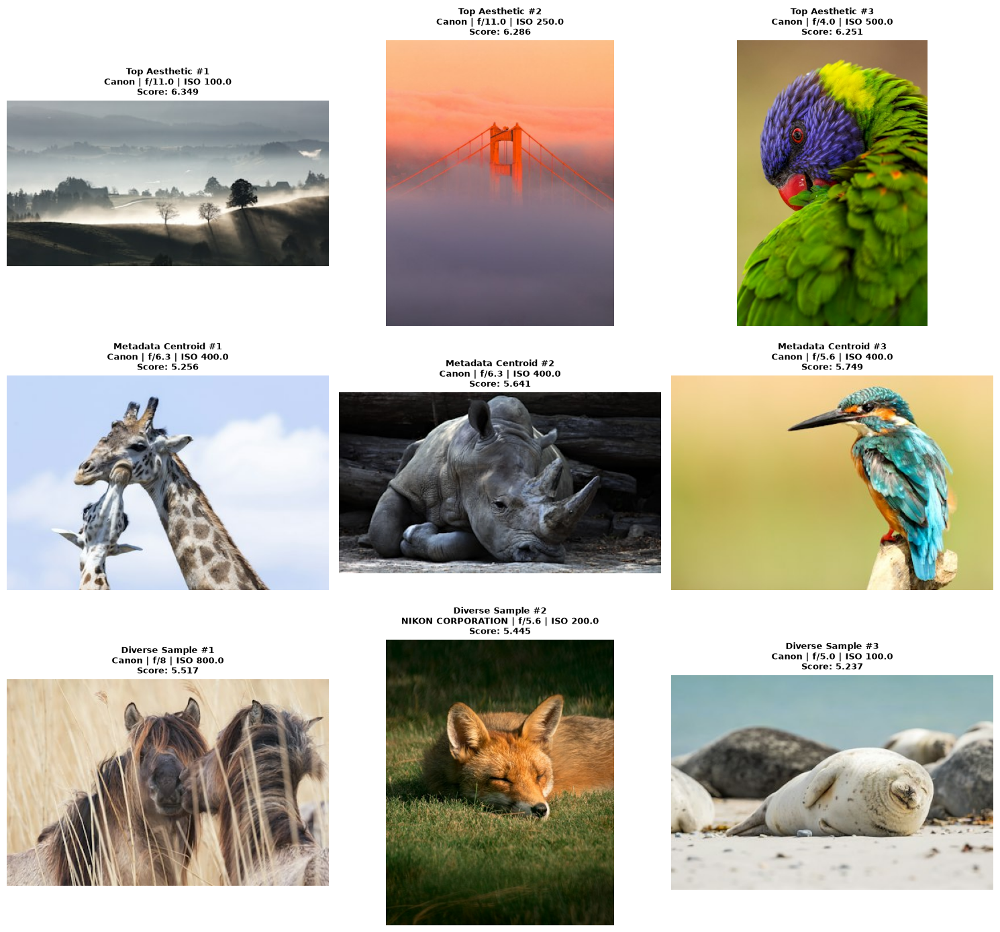

---------------------------------------------------------------------------------------------------------


In [13]:
import io
import requests
from PIL import Image

session = requests.Session()
meta_centers = kmeans_meta.cluster_centers_

print("=" * 105)
print(f"EXIF + TAG DRIVEN CLUSTERS (9 PHOTOS PER CLUSTER) | k = {optimal_k_meta}")
print("=" * 105)

for cid in sorted(df_photos["meta_cluster_id"].unique()):
    c_mask = df_photos["meta_cluster_id"] == cid
    cluster_df = df_photos[c_mask]
    cluster_size = len(cluster_df)
    pct = (cluster_size / len(df_photos)) * 100
    
    # 1. Semantic Tag Breakdown
    cluster_tags = []
    for pid in cluster_df["photo_id"]:
        if pid in photo_to_tags:
            cluster_tags.extend(photo_to_tags[pid])
            
    top_tags = (
        pd.Series(cluster_tags).value_counts().head(6).index.str.replace("Tag_", "").tolist()
        if cluster_tags else ["N/A"]
    )
    
    # 2. Technical Profile
    mean_iso = pd.to_numeric(cluster_df["exif_iso"], errors="coerce").median()
    mean_ap = pd.to_numeric(cluster_df["exif_aperture_value"], errors="coerce").median()
    top_make = cluster_df["exif_camera_make"].dropna().mode().iloc[0] if not cluster_df["exif_camera_make"].dropna().empty else "N/A"
    
    mean_score = cluster_df["predicted_aesthetic_score"].mean()
    high_pct = (cluster_df["aesthetic_bin"] == "High_Aesthetic").mean() * 100
    
    # 3. Select 9 Images: Top 3 Aesthetic, 3 Medoids, 3 Diverse
    cluster_indices = np.where(c_mask)[0]
    cluster_vecs = X_meta[c_mask]
    center_vec = meta_centers[cid]
    
    # Row 1: Top 3 Aesthetic
    top_3_aesthetic = cluster_df.sort_values(by="predicted_aesthetic_score", ascending=False).head(3)
    
    # Row 2: 3 Medoids
    dists = np.linalg.norm(cluster_vecs - center_vec, axis=1)
    medoid_indices = np.argsort(dists)[:3]
    top_3_medoids = df_photos.iloc[cluster_indices[medoid_indices]]
    
    # Row 3: 3 Diverse Samples
    picked_ids = set(top_3_aesthetic["photo_id"]).union(set(top_3_medoids["photo_id"]))
    rem_df = cluster_df[~cluster_df["photo_id"].isin(picked_ids)]
    diverse_samples = rem_df.sample(n=min(3, len(rem_df)), random_state=42) if len(rem_df) >= 3 else rem_df
    
    gallery = []
    for rank, (_, row) in enumerate(top_3_aesthetic.iterrows(), start=1):
        gallery.append((f"Top Aesthetic #{rank}", row))
    for rank, (_, row) in enumerate(top_3_medoids.iterrows(), start=1):
        gallery.append((f"Metadata Centroid #{rank}", row))
    for rank, (_, row) in enumerate(diverse_samples.iterrows(), start=1):
        gallery.append((f"Diverse Sample #{rank}", row))
        
    print(f"\n[METADATA CLUSTER {cid:2d}] Size: {cluster_size:,} ({pct:4.1f}%) | Mean Score: {mean_score:.3f} | High Aesthetic: {high_pct:4.1f}%")
    print(f"  Dominant Hardware Profile : Make: {top_make} | Median Aperture: f/{mean_ap:.1f} | Median ISO: {mean_iso:.0f}")
    print(f"  Top Semantic Tags         : {', '.join(top_tags)}")
    
    # Render 3x3 Grid
    fig, axes = plt.subplots(3, 3, figsize=(15, 14))
    axes = axes.flatten()
    
    for ax, (label_title, row) in zip(axes, gallery):
        url = str(row.get("photo_image_url", ""))
        fetch_url = f"{url}?w=400&q=80" if "?" not in url else f"{url}&w=400&q=80"
        
        img = None
        if url:
            try:
                res = session.get(fetch_url, timeout=10)
                if res.status_code == 200:
                    img = Image.open(io.BytesIO(res.content))
            except Exception:
                pass
                
        if img:
            ax.imshow(img)
            ax.axis("off")
            score_val = row.get("predicted_aesthetic_score", 0.0)
            ap_val = row.get("exif_aperture_value", "N/A")
            iso_val = row.get("exif_iso", "N/A")
            make_val = row.get("exif_camera_make", "N/A")
            ax.set_title(
                f"{label_title}\n{make_val} | f/{ap_val} | ISO {iso_val}\nScore: {score_val:.3f}",
                fontsize=9, fontweight="semibold"
            )
        else:
            ax.text(0.5, 0.5, "Image load failed", ha="center", va="center")
            ax.axis("off")
            
    for extra_ax in axes[len(gallery):]:
        extra_ax.axis("off")
        
    plt.tight_layout()
    plt.show()
    print("-" * 105)